# Automated ICD-10 Code Prediction from Clinical Notes
### Using Machine Learning and Explainable NLP

**Goal.** Predict the ICD-10-CM diagnosis code of a clinical case narrative, compare a classical NLP model with sentence-embedding models, and explain where and why the models succeed or fail.

| | |
|---|---|
| **Dataset** | [`mkurman/clinical-case-icd10-diagnosis`](https://huggingface.co/datasets/mkurman/clinical-case-icd10-diagnosis) (Hugging Face) - 1,798 English case narratives from open-access PubMed Central case reports |
| **Task** | Single-label multiclass text classification: clinical narrative -> one ICD-10-CM code |
| **Model 1** | TF-IDF + Logistic Regression (classical baseline) |
| **Model 2** | Sentence embeddings + Logistic Regression, with two encoders: a general one (`all-MiniLM-L6-v2`) and a biomedical one (`NeuML/pubmedbert-base-embeddings`) |
| **Combined model** | Reciprocal rank fusion of Models 1 and 2 |
| **Web app** | **Chart2Code**: paste, upload, scan (OCR) or dictate a note and get ICD-10 suggestions with highlighted evidence (`webapp/` folder, Section 14) |
| **Evaluation** | Publication-grouped train/test split, hyperparameters tuned with grouped cross-validation on the training set only, accuracy, top-3/top-5 accuracy, macro/weighted F1, precision, recall |

**Workflow**

1. Load the dataset and inspect its structure
2. Exploratory data analysis (labels, text length, data quality)
3. Define the classification task and prepare labels
4. Light text preprocessing
5. Publication-aware train/test split (no leakage)
6. Model 1: TF-IDF + Logistic Regression (tuned with grouped CV)
7. Model 2: Sentence embeddings + Logistic Regression (tuned with grouped CV)
8. Evaluation and model comparison, a cross-validation robustness check, and a combined model
9. Explainability (influential words, top-k probabilities, similar training cases)
10. Error analysis
11. Demo predictor, results summary, discussion and limitations
12. Web application (Chart2Code)

> **Disclaimer.** This is an academic experiment. It is not a clinical decision-making system and is not a replacement for professional medical coders.

*Runs on Google Colab (CPU is enough, a GPU makes the embedding step faster) or any local Python 3.10+ environment. Full run time: about 5-10 minutes.*

## 0. Setup

In [1]:
!pip install -q datasets sentence-transformers

import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Small classes trigger a harmless "least populated class" warning in stratified CV
warnings.filterwarnings("ignore", message="The least populated class")
warnings.filterwarnings("ignore", message="A worker stopped")  # harmless joblib notice

# One fixed colour per model, used in every chart
MODEL_COLORS = {
    "Majority baseline": "#9e9c96",
    "TF-IDF + LR": "#2a78d6",
    "MiniLM + LR": "#eb6834",
    "PubMedBERT + LR": "#1baf7a",
}
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.dpi": 110,
})

# Figures are also saved here for the report / slides
os.makedirs("figures", exist_ok=True)

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

zsh:1: command not found: pip


Libraries imported successfully!
Pandas version: 3.1.0
NumPy version: 2.5.4


/private/tmp/claude-501/-Users-aviral/222bd01f-83dd-40f9-856a-acd42748f4a3/scratchpad/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Dataset Loading and Initial Inspection

Load the dataset from Hugging Face, convert it to a DataFrame and check columns, missing values and duplicates before making any modeling decision.

In [2]:
# Load the dataset from Hugging Face

dataset = load_dataset("mkurman/clinical-case-icd10-diagnosis")

# Display the dataset structure
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['case_id', 'input', 'output', 'icd10_code', 'diagnosis', 'status', 'pmcid', 'pmid', 'doi', 'source', 'source_url', 'license', 'license_url', 'is_open_access', 'license_category'],
        num_rows: 1798
    })
})


In [3]:
# Convert the training split into a Pandas DataFrame

df = dataset["train"].to_pandas()

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display the first 3 records
print("\nFirst 3 records:")
display(df.head(3))

Dataset shape: (1798, 15)

Column names:
['case_id', 'input', 'output', 'icd10_code', 'diagnosis', 'status', 'pmcid', 'pmid', 'doi', 'source', 'source_url', 'license', 'license_url', 'is_open_access', 'license_category']

First 3 records:


,case_id,input,output,icd10_code,diagnosis,status,pmcid,pmid,doi,source,source_url,license,license_url,is_open_access,license_category
0,ED0001,A man in his late 50s was referred to the hosp...,"{'icd10_code': 'E23.0', 'name': 'Hypopituitari...",E23.0,Hypopituitarism,ACUTE,PMC10017242,35705269,10.2169/internalmedicine.0031-22,PubMed Central (open access subset),https://www.ncbi.nlm.nih.gov/pmc/articles/PMC1...,CC BY-NC-ND 4.0,https://creativecommons.org/licenses/by-nc-nd/...,True,non_commercial
1,ED0002,A man in his late 60s with a recently diagnose...,"{'icd10_code': 'J05.11', 'name': 'Acute epiglo...",J05.11,Acute epiglottitis with obstruction,ACUTE,PMC10026303,36690392,10.1002/cnr2.1783,PubMed Central (open access subset),https://www.ncbi.nlm.nih.gov/pmc/articles/PMC1...,CC BY 4.0,https://creativecommons.org/licenses/by/4.0/,True,commercial
2,ED0003,"A 54-year-old male, otherwise healthy, with a ...","{'icd10_code': 'I82.4Z2', 'name': 'Acute embol...",I82.4Z2,Acute embolism and thrombosis of unspecified d...,ACUTE,PMC10061352,36966353,10.12659/AJCR.938677,PubMed Central (open access subset),https://www.ncbi.nlm.nih.gov/pmc/articles/PMC1...,CC BY-NC-ND 4.0,https://creativecommons.org/licenses/by-nc-nd/...,True,non_commercial


In [4]:
# Inspect data types and missing values

print("Data types:")
print(df.dtypes)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nPercentage of missing values:")
print((df.isnull().mean() * 100).round(2))

Data types:
case_id                str
input                  str
output              object
icd10_code             str
diagnosis              str
status                 str
pmcid                  str
pmid                   str
doi                    str
source                 str
source_url             str
license                str
license_url            str
is_open_access      object
license_category       str
dtype: object

Missing values in each column:
case_id              0
input                0
output               0
icd10_code           0
diagnosis            0
status               0
pmcid                0
pmid                69
doi                  1
source               0
source_url           0
license              0
license_url         19
is_open_access       6
license_category     0
dtype: int64

Percentage of missing values:
case_id             0.00
input               0.00
output              0.00
icd10_code          0.00
diagnosis           0.00
status              0.0

In [5]:
# Check duplicates using hashable columns

print("Duplicate case IDs:", df["case_id"].duplicated().sum())

print("Duplicate clinical narratives:", df["input"].duplicated().sum())

print("Duplicate ICD-10 codes:", df["icd10_code"].duplicated().sum())

# Check duplicate rows using selected columns
duplicate_check = df[
    ["case_id", "input", "icd10_code", "diagnosis"]
].duplicated()

print("Duplicate rows (selected columns):", duplicate_check.sum())

Duplicate case IDs: 0
Duplicate clinical narratives: 0
Duplicate ICD-10 codes: 803
Duplicate rows (selected columns): 0


**Observations**

- One split (`train`) with **1,798 records** and 15 columns.
- Clinical text column: `input`. Target: `icd10_code`. Diagnosis description: `diagnosis`. Publication identifier: `pmcid`.
- No missing values in the text, code, diagnosis or `pmcid` columns (only bibliographic metadata such as `pmid`/`doi` has gaps, which we do not use).
- No duplicate case IDs, narratives or rows.

## 2. Exploratory Data Analysis

### 2.1 Label distribution

In [6]:
# Analyze ICD-10 code distribution

code_counts = df["icd10_code"].value_counts()

print("Total unique ICD-10 codes:", df["icd10_code"].nunique())

print("\nTop 20 most frequent ICD-10 codes:")
display(code_counts.head(20).to_frame(name="case_count"))

print("\nDescriptive statistics of code frequencies:")
print(code_counts.describe())

Total unique ICD-10 codes: 995

Top 20 most frequent ICD-10 codes:


,case_count
icd10_code,
I33.0,36
E05.01,20
G04.81,20
I71.019,16
G61.0,14
E10.10,13
G70.01,12
I71.03,12
I26.09,11



Descriptive statistics of code frequencies:
count    995.000000
mean       1.807035
std        2.102253
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max       36.000000
Name: count, dtype: float64


In [7]:
# Detailed ICD-10 class frequency analysis

print("Codes appearing exactly once:",
      (code_counts == 1).sum())

print("Codes appearing exactly twice:",
      (code_counts == 2).sum())

print("Codes with at least 3 cases:",
      (code_counts >= 3).sum())

print("Codes with at least 5 cases:",
      (code_counts >= 5).sum())

print("Codes with at least 10 cases:",
      (code_counts >= 10).sum())

print("\nFrequency distribution:")
frequency_distribution = code_counts.value_counts().sort_index()
display(frequency_distribution.to_frame(name="number_of_codes"))

Codes appearing exactly once: 675
Codes appearing exactly twice: 161
Codes with at least 3 cases: 159
Codes with at least 5 cases: 58
Codes with at least 10 cases: 12

Frequency distribution:


,number_of_codes
count,
1,675
2,161
3,63
4,38
5,21
6,12
7,7
8,5
9,1


### 2.2 Text length

In [8]:
# Calculate clinical note lengths

df["note_length_words"] = df["input"].apply(
    lambda x: len(str(x).split())
)

df["note_length_characters"] = df["input"].apply(
    lambda x: len(str(x))
)

print("Word count statistics:")
print(df["note_length_words"].describe())

print("\nCharacter count statistics:")
print(df["note_length_characters"].describe())

print("\nShortest clinical note (words):",
      df["note_length_words"].min())

print("Longest clinical note (words):",
      df["note_length_words"].max())

Word count statistics:
count    1798.000000
mean      211.886541
std        27.702358
min       120.000000
25%       194.000000
50%       211.000000
75%       229.000000
max       327.000000
Name: note_length_words, dtype: float64

Character count statistics:
count    1798.000000
mean     1523.489433
std       211.397935
min       814.000000
25%      1390.000000
50%      1519.000000
75%      1652.000000
max      2405.000000
Name: note_length_characters, dtype: float64

Shortest clinical note (words): 120
Longest clinical note (words): 327


### 2.3 Label consistency checks

In [9]:
# Check whether each ICD-10 code maps to one diagnosis

code_diagnosis_counts = (
    df.groupby("icd10_code")["diagnosis"]
    .nunique()
    .sort_values(ascending=False)
)

print("Codes mapped to multiple diagnoses:",
      (code_diagnosis_counts > 1).sum())

print("\nMaximum number of diagnoses for one code:",
      code_diagnosis_counts.max())

print("\nExamples of codes with multiple diagnoses:")

multi_diagnosis_codes = code_diagnosis_counts[
    code_diagnosis_counts > 1
].index

display(
    df[df["icd10_code"].isin(multi_diagnosis_codes)]
    [["icd10_code", "diagnosis"]]
    .drop_duplicates()
    .head(20)
)

Codes mapped to multiple diagnoses: 0

Maximum number of diagnoses for one code: 1

Examples of codes with multiple diagnoses:


,icd10_code,diagnosis


In [10]:
# Inspect the structure of the output column

print("Output data type:", type(df["output"].iloc[0]))

print("\nFirst output record:")
print(df["output"].iloc[0])

# Extract embedded ICD-10 codes and diagnosis names
df["output_icd10_code"] = df["output"].apply(
    lambda x: x.get("icd10_code") if isinstance(x, dict) else None
)

df["output_diagnosis"] = df["output"].apply(
    lambda x: x.get("name") if isinstance(x, dict) else None
)

# Check consistency
print("\nICD-10 code mismatches:",
      (df["icd10_code"] != df["output_icd10_code"]).sum())

print("Diagnosis mismatches:",
      (df["diagnosis"] != df["output_diagnosis"]).sum())

Output data type: <class 'dict'>

First output record:
{'icd10_code': 'E23.0', 'name': 'Hypopituitarism', 'status': 'ACUTE'}

ICD-10 code mismatches: 0
Diagnosis mismatches: 0


In [11]:
# Analyze status distribution

print("Unique status values:")
print(df["status"].unique())

print("\nStatus frequency:")
status_counts = df["status"].value_counts(dropna=False)

display(status_counts.to_frame(name="case_count"))

print("\nStatus percentages:")
display(
    (df["status"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
    .to_frame(name="percentage")
)

Unique status values:
<ArrowStringArray>
['ACUTE', 'CHRONIC']
Length: 2, dtype: str

Status frequency:


,case_count
status,
ACUTE,1309
CHRONIC,489



Status percentages:


,percentage
status,
ACUTE,72.8
CHRONIC,27.2


In [12]:
# ==========================================
# DOES THE NARRATIVE GIVE AWAY THE ANSWER?
# ==========================================

diagnosis_lower = df["diagnosis"].str.lower()
note_lower = df["input"].str.lower()
first_two_words = diagnosis_lower.str.split().str[:2].str.join(" ")

print("Notes containing the full diagnosis name:",
      f"{np.mean([d in n for d, n in zip(diagnosis_lower, note_lower)]) * 100:.1f}%")
print("Notes containing the first two words of the diagnosis name:",
      f"{np.mean([d in n for d, n in zip(first_two_words, note_lower)]) * 100:.1f}%")

for code_, word in [("I33.0", "endocarditis"), ("E05.01", "storm"), ("G61.0", "guillain"), ("E10.10", "ketoacidosis")]:
    notes = note_lower[df["icd10_code"] == code_]
    print(f"  {code_} notes mentioning '{word}': {notes.str.contains(word).mean() * 100:.0f}% of {len(notes)}")

Notes containing the full diagnosis name: 0.2%
Notes containing the first two words of the diagnosis name: 1.8%
  I33.0 notes mentioning 'endocarditis': 0% of 36
  E05.01 notes mentioning 'storm': 0% of 20
  G61.0 notes mentioning 'guillain': 0% of 14
  E10.10 notes mentioning 'ketoacidosis': 0% of 13


### 2.4 EDA charts

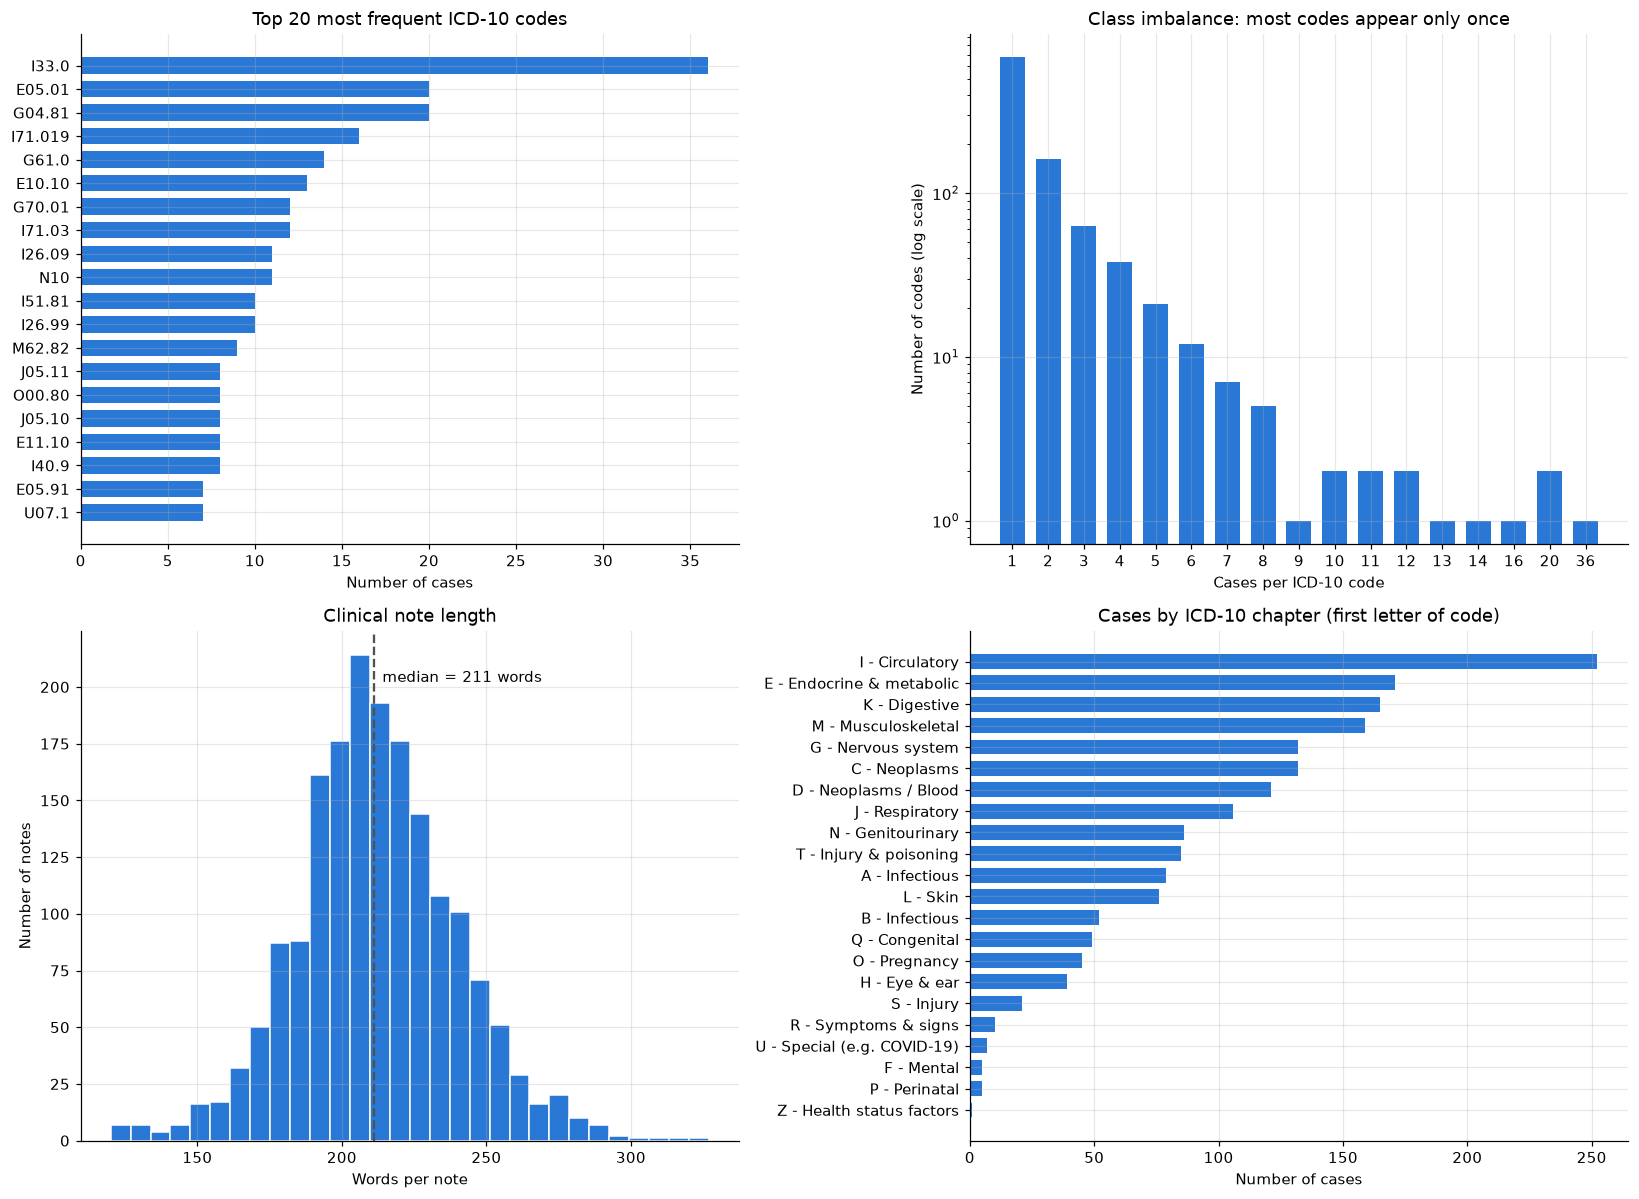

In [13]:
# ==========================================
# EDA CHARTS
# ==========================================

ICD10_CHAPTERS = {
    "A": "Infectious", "B": "Infectious", "C": "Neoplasms", "D": "Neoplasms / Blood",
    "E": "Endocrine & metabolic", "F": "Mental", "G": "Nervous system", "H": "Eye & ear",
    "I": "Circulatory", "J": "Respiratory", "K": "Digestive", "L": "Skin",
    "M": "Musculoskeletal", "N": "Genitourinary", "O": "Pregnancy", "P": "Perinatal",
    "Q": "Congenital", "R": "Symptoms & signs", "S": "Injury", "T": "Injury & poisoning",
    "U": "Special (e.g. COVID-19)", "V": "External causes", "W": "External causes",
    "X": "External causes", "Y": "External causes", "Z": "Health status factors",
}
BLUE = MODEL_COLORS["TF-IDF + LR"]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Top 20 codes
top20 = code_counts.head(20)[::-1]
axes[0, 0].barh(top20.index, top20.values, color=BLUE, height=0.7)
axes[0, 0].set_title("Top 20 most frequent ICD-10 codes")
axes[0, 0].set_xlabel("Number of cases")

# Long tail: how many codes have 1, 2, 3, ... cases
freq = code_counts.value_counts().sort_index()
axes[0, 1].bar(freq.index.astype(str), freq.values, color=BLUE, width=0.7)
axes[0, 1].set_yscale("log")
axes[0, 1].set_title("Class imbalance: most codes appear only once")
axes[0, 1].set_xlabel("Cases per ICD-10 code")
axes[0, 1].set_ylabel("Number of codes (log scale)")

# Note length
axes[1, 0].hist(df["note_length_words"], bins=30, color=BLUE, edgecolor="white")
median_words = df["note_length_words"].median()
axes[1, 0].axvline(median_words, color="#52514e", linestyle="--", linewidth=1.5)
axes[1, 0].text(median_words + 3, axes[1, 0].get_ylim()[1] * 0.9, f"median = {median_words:.0f} words")
axes[1, 0].set_title("Clinical note length")
axes[1, 0].set_xlabel("Words per note")
axes[1, 0].set_ylabel("Number of notes")

# ICD-10 chapter (first letter of the code)
df["icd10_chapter"] = df["icd10_code"].str[0]
chapters = df["icd10_chapter"].value_counts().sort_values()
chapter_labels = [f"{c} - {ICD10_CHAPTERS.get(c, '?')}" for c in chapters.index]
axes[1, 1].barh(chapter_labels, chapters.values, color=BLUE, height=0.7)
axes[1, 1].set_title("Cases by ICD-10 chapter (first letter of code)")
axes[1, 1].set_xlabel("Number of cases")

plt.tight_layout()
plt.savefig("figures/eda_overview.png", bbox_inches="tight")
plt.show()

**EDA findings**

- **995 unique codes for 1,798 notes.** 675 codes (68%) appear only once and only 58 codes have 5 or more cases. The label space is extremely long-tailed.
- A code that appears once cannot be both learned and tested, so the full 995-class problem is not learnable from this data.
- Notes are consistently sized: about 120-327 words (median 211), so no empty or extremely short narratives.
- **The narratives hide the final diagnosis.** By design (per the dataset card) the diagnosis is removed from each history; our check confirms the diagnosis name almost never appears in the note (e.g. none of the endocarditis notes contain the word "endocarditis"). Models must infer the code from symptoms, examination and test results, not from a keyword.
- **Every record has exactly one code** (`output` dict matches `icd10_code` 100%; every code maps to exactly one diagnosis name). The task is genuinely single-label.
- Cases span most ICD-10 chapters, with circulatory (I), endocrine (E) and nervous system (G) the largest.

## 3. Classification Task and Label Preparation

**Task:** single-label multiclass classification, `input` (clinical narrative) -> `icd10_code`.

Because most codes are too rare to learn, we restrict the experiment to codes with a minimum number of cases. The tables below compare candidate thresholds.

In [14]:
# ==========================================
# COMPARE MODELING CLASS THRESHOLDS
# ==========================================

thresholds = [3, 5, 8, 10, 15]

comparison = []

for threshold in thresholds:
    valid_codes = code_counts[
        code_counts >= threshold
    ].index

    subset = df[
        df["icd10_code"].isin(valid_codes)
    ]

    comparison.append({
        "Minimum cases per class": threshold,
        "Selected classes": subset["icd10_code"].nunique(),
        "Selected records": len(subset),
        "Excluded records": len(df) - len(subset),
        "Minimum class size": (
            subset["icd10_code"].value_counts().min()
            if len(subset) > 0 else 0
        )
    })

threshold_comparison = pd.DataFrame(comparison)

display(threshold_comparison)

,Minimum cases per class,Selected classes,Selected records,Excluded records,Minimum class size
0,3,159,801,997,3
1,5,58,460,1338,5
2,8,18,234,1564,8
3,10,12,185,1613,10
4,15,4,92,1706,16


In [15]:
# ==========================================
# CREATE MODELING SUBSETS
# ==========================================

thresholds = [3, 4, 5]
modeling_datasets = {}
summary = []

for threshold in thresholds:

    valid_codes = code_counts[
        code_counts >= threshold
    ].index

    subset = df[
        df["icd10_code"].isin(valid_codes)
    ][
        ["input", "icd10_code", "diagnosis"]
    ].copy().reset_index(drop=True)

    modeling_datasets[threshold] = subset

    summary.append({
        "Threshold": f">= {threshold}",
        "Classes": subset["icd10_code"].nunique(),
        "Records": len(subset),
        "Excluded": len(df) - len(subset),
        "Minimum class size": subset["icd10_code"].value_counts().min(),
        "Median class size": subset["icd10_code"].value_counts().median()
    })

threshold_summary = pd.DataFrame(summary)

print("Threshold comparison:")
display(threshold_summary)

# Store the datasets separately
model_df_3 = modeling_datasets[3]
model_df_4 = modeling_datasets[4]
model_df_5 = modeling_datasets[5]

print("\nDataset shapes:")
print(">= 3:", model_df_3.shape)
print(">= 4:", model_df_4.shape)
print(">= 5:", model_df_5.shape)

Threshold comparison:


,Threshold,Classes,Records,Excluded,Minimum class size,Median class size
0,>= 3,159,801,997,3,4.0
1,>= 4,96,612,1186,4,5.0
2,>= 5,58,460,1338,5,6.0



Dataset shapes:
>= 3: (801, 3)
>= 4: (612, 3)
>= 5: (460, 3)


**Decision.** We run two experiments:

- **>= 4 cases per code:** 96 classes, 612 records (harder: more classes, fewer examples each)
- **>= 5 cases per code:** 58 classes, 460 records (primary experiment)

Threshold 3 would leave many classes with a single training example after splitting; thresholds of 8 or more keep too few classes (18 or fewer) to be an interesting coding problem. Labels are kept as the original ICD-10 code strings, which scikit-learn encodes internally, so predictions map straight back to codes.

## 4. Text Preprocessing

Preprocessing is deliberately light. Medical terms, numbers, units and negations ("no fever", "denied chest pain") carry diagnostic meaning, so we only normalise whitespace. Tokenisation and lower-casing are handled by the TF-IDF vectoriser and the sentence-transformer tokenisers.

In [16]:
# ==========================================
# LIGHT TEXT CLEANING
# ==========================================

def clean_text(text):
    """Normalise whitespace only; keep clinical wording intact."""
    text = str(text).replace(" ", " ")
    return re.sub(r"\s+", " ", text).strip()

df["clean_input"] = df["input"].apply(clean_text)

print("Notes changed by whitespace normalisation:", (df["clean_input"] != df["input"]).sum())
print("Empty notes after cleaning:", (df["clean_input"].str.len() == 0).sum())

code_to_diagnosis = df.drop_duplicates("icd10_code").set_index("icd10_code")["diagnosis"]

Notes changed by whitespace normalisation: 42
Empty notes after cleaning: 0


## 5. Train/Test Strategy (publication-aware, no leakage)

- 80/20 split with `GroupShuffleSplit`, grouped by **publication (`pmcid`)**, so cases from the same article never appear in both train and test.
- Among candidate splits we pick the first one in which **every class appears in training** (otherwise the model could never predict that class).
- The test set is used **once**, for the final evaluation. All tuning happens with cross-validation inside the training set (Sections 6 and 7).
- The TF-IDF vectoriser and all classifiers are fitted on training data only.

In [17]:
# ==========================================
# FINAL DATA PREPARATION
# PUBLICATION-AWARE TRAIN/TEST SPLIT
# ==========================================

import pandas as pd
import numpy as np

from sklearn.model_selection import GroupShuffleSplit

RANDOM_STATE = 42
TEST_SIZE = 0.20

# Recreate datasets while retaining publication identifiers
experiments = {}

for threshold in [4, 5]:

    valid_codes = code_counts[
        code_counts >= threshold
    ].index

    data = df[
        df["icd10_code"].isin(valid_codes)
    ][
        ["clean_input", "icd10_code", "diagnosis", "pmcid", "case_id"]
    ].copy().reset_index(drop=True)

    # Use case_id when PMCID is missing
    data["split_group"] = data["pmcid"].fillna(
        data["case_id"].astype(str)
    )

    experiments[f"threshold_{threshold}"] = data


splits = {}

for name, data in experiments.items():

    X = data["clean_input"]
    y = data["icd10_code"]
    groups = data["split_group"]

    all_classes = set(y.unique())

    splitter = GroupShuffleSplit(
        n_splits=500,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE
    )

    selected_split = None
    best_split = None
    best_score = None

    for train_idx, test_idx in splitter.split(
        X, y, groups
    ):

        y_train_candidate = y.iloc[train_idx]
        y_test_candidate = y.iloc[test_idx]

        missing_train = len(
            all_classes - set(y_train_candidate)
        )

        missing_test = len(
            all_classes - set(y_test_candidate)
        )

        size_difference = abs(
            len(test_idx) - round(len(data) * TEST_SIZE)
        )

        score = (
            missing_train,
            missing_test,
            size_difference
        )

        if best_score is None or score < best_score:
            best_score = score
            best_split = (train_idx, test_idx)

        # Prefer splits containing every class in training
        if missing_train == 0:
            selected_split = (train_idx, test_idx)
            break

    if selected_split is None:
        selected_split = best_split
        print(
            f"Warning: No ideal split found for {name}. "
            "Using the closest available split."
        )

    train_idx, test_idx = selected_split

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    train_groups = set(groups.iloc[train_idx])
    test_groups = set(groups.iloc[test_idx])

    overlapping_groups = train_groups.intersection(
        test_groups
    )

    splits[name] = {
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test,
        "groups_train": groups.iloc[train_idx]
    }

    print("\n" + "=" * 65)
    print(f"EXPERIMENT: {name}")
    print("=" * 65)

    print("Total records:", len(data))
    print("Total classes:", y.nunique())
    print("Training records:", len(X_train))
    print("Testing records:", len(X_test))
    print("Training classes:", y_train.nunique())
    print("Testing classes:", y_test.nunique())
    print(
        "Minimum training class count:",
        y_train.value_counts().min()
    )
    print(
        "Minimum testing class count:",
        y_test.value_counts().min()
    )
    print("Publication groups in training:", len(train_groups))
    print("Publication groups in testing:", len(test_groups))
    print("Overlapping publication groups:", len(overlapping_groups))

    if overlapping_groups:
        print("WARNING: Publication overlap detected.")
    else:
        print("No publication overlap detected.")


EXPERIMENT: threshold_4
Total records: 612
Total classes: 96
Training records: 489
Testing records: 123
Training classes: 96
Testing classes: 67
Minimum training class count: 1
Minimum testing class count: 1
Publication groups in training: 487
Publication groups in testing: 122
Overlapping publication groups: 0
No publication overlap detected.

EXPERIMENT: threshold_5
Total records: 460
Total classes: 58
Training records: 368
Testing records: 92
Training classes: 58
Testing classes: 46
Minimum training class count: 2
Minimum testing class count: 1
Publication groups in training: 366
Publication groups in testing: 92
Overlapping publication groups: 0
No publication overlap detected.


**Result.** No publication overlap between train and test in either experiment, and every class is present in training. Many test classes have only 1-2 examples, so each test case moves accuracy by about 1 percentage point; Section 8.3 adds a cross-validation check to measure that variance.

## 6. Model 1: TF-IDF + Logistic Regression

```
Clinical narrative -> TF-IDF (words / word pairs) -> Logistic Regression -> ICD-10 code
```

**Hyperparameter tuning.** A 3-fold `StratifiedGroupKFold` cross-validation on the *training set only* (grouped by publication) chooses:

- n-gram range: unigrams vs unigrams + bigrams
- minimum document frequency: 1 vs 2
- regularisation strength `C`: 1, 10, 100

`class_weight="balanced"` counters the class imbalance. Stop words are **not** removed, because the English stop-word list contains negations such as "no" and "not".

*Note:* an earlier version used `solver="liblinear"`. Recent scikit-learn releases (1.8+) no longer allow `liblinear` for multiclass problems, so the notebook now uses the default `lbfgs` solver (a true multinomial model), which works on every version.

In [18]:
# ==========================================
# SHARED EVALUATION HELPER
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    top_k_accuracy_score,
)
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV

# Grouped CV used for all tuning (training data only)
tuning_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)


def evaluate(y_true, y_pred, proba, classes):
    """All metrics used in the project, computed the same way for every model."""
    wp, wr, wf1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    mp, mr, mf1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "top3_accuracy": top_k_accuracy_score(y_true, proba, k=3, labels=classes),
        "top5_accuracy": top_k_accuracy_score(y_true, proba, k=5, labels=classes),
        "macro_precision": mp,
        "macro_recall": mr,
        "macro_f1": mf1,
        "weighted_precision": wp,
        "weighted_recall": wr,
        "weighted_f1": wf1,
    }


# Everything is stored under (model name, experiment name)
fitted, results, predictions, probabilities, tuning = {}, {}, {}, {}, []


def record(model_name, experiment_name, model, X_test, y_test, search=None):
    proba = model.predict_proba(X_test)
    y_pred = model.classes_[proba.argmax(axis=1)]
    key = (model_name, experiment_name)
    fitted[key], predictions[key], probabilities[key] = model, y_pred, proba
    results[key] = evaluate(y_test, y_pred, proba, model.classes_)
    if search is not None:
        tuning.append({
            "Model": model_name,
            "Dataset": experiment_name,
            "Best parameters": search.best_params_,
            "CV accuracy (train only)": round(search.best_score_, 4),
        })
    m = results[key]
    print(f"{model_name:16s} | {experiment_name}: accuracy {m['accuracy']:.4f} | "
          f"top-5 {m['top5_accuracy']:.4f} | macro F1 {m['macro_f1']:.4f} | weighted F1 {m['weighted_f1']:.4f}")

In [19]:
# ==========================================
# MODEL 1: TF-IDF + LOGISTIC REGRESSION
# ==========================================

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

tfidf_param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2],
    "clf__C": [1, 10, 100],
}

for experiment_name, split_data in splits.items():

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, sublinear_tf=True)),
        ("clf", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE)),
    ])

    search = GridSearchCV(pipeline, tfidf_param_grid, cv=tuning_cv, scoring="accuracy", n_jobs=-1)
    search.fit(split_data["X_train"], split_data["y_train"], groups=split_data["groups_train"])

    # best_estimator_ is refitted on the whole training set
    record("TF-IDF + LR", experiment_name, search.best_estimator_,
           split_data["X_test"], split_data["y_test"], search)
    print("   best parameters:", search.best_params_,
          "| TF-IDF features:", len(search.best_estimator_.named_steps["tfidf"].vocabulary_))

TF-IDF + LR      | threshold_4: accuracy 0.3902 | top-5 0.7236 | macro F1 0.2524 | weighted F1 0.3364
   best parameters: {'clf__C': 10, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)} | TF-IDF features: 7245


TF-IDF + LR      | threshold_5: accuracy 0.5109 | top-5 0.8587 | macro F1 0.3641 | weighted F1 0.4810
   best parameters: {'clf__C': 1, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)} | TF-IDF features: 44755


### 6.1 Detailed TF-IDF evaluation


DETAILED EVALUATION: threshold_4

Classification Report:
              precision    recall  f1-score   support

       A15.0       0.00      0.00      0.00         1
      B44.81       0.00      0.00      0.00         0
      C34.32       0.00      0.00      0.00         0
      C83.30       0.00      0.00      0.00         1
      C83.38       0.00      0.00      0.00         0
      C91.10       0.00      0.00      0.00         1
      C92.00       0.50      1.00      0.67         1
      C95.00       1.00      0.50      0.67         4
      D35.00       0.00      0.00      0.00         3
      D35.01       0.00      0.00      0.00         0
      D35.02       0.50      0.50      0.50         2
         D65       0.00      0.00      0.00         1
       D69.0       1.00      0.50      0.67         2
      D89.84       0.00      0.00      0.00         0
      E05.01       0.40      1.00      0.57         6
      E05.30       0.00      0.00      0.00         1
      E05.91       0.00

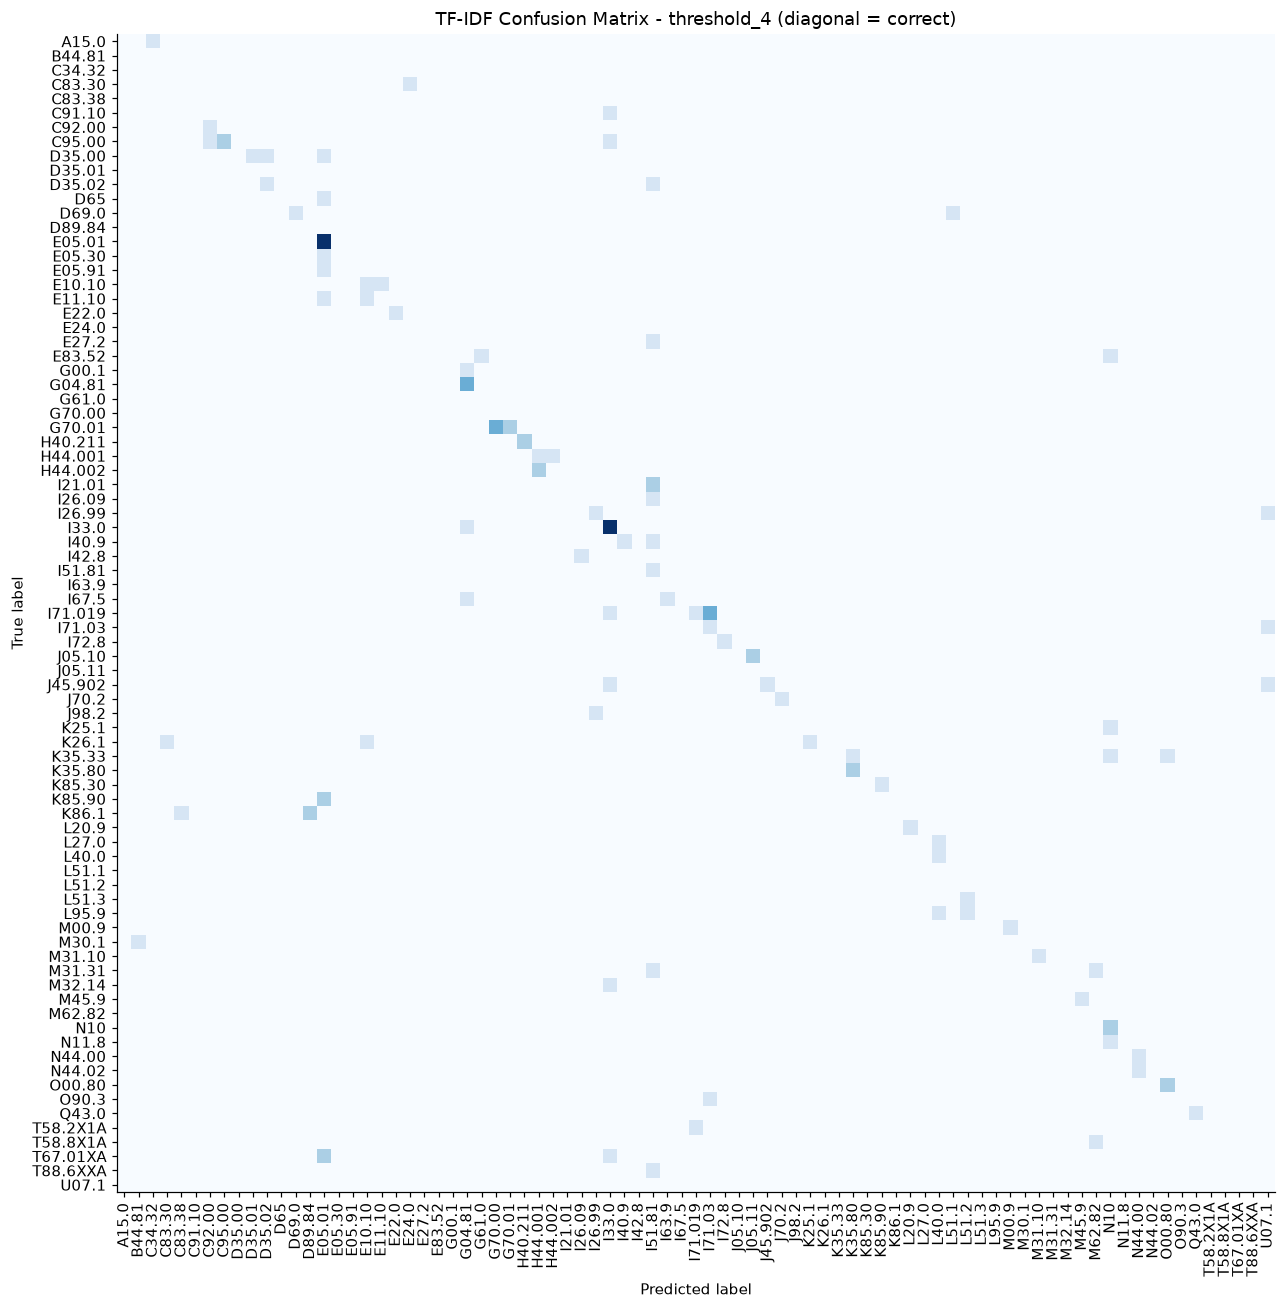


DETAILED EVALUATION: threshold_5

Classification Report:
              precision    recall  f1-score   support

      C91.10       0.00      0.00      0.00         2
      C92.00       0.00      0.00      0.00         1
      C95.00       0.00      0.00      0.00         0
      D35.00       0.00      0.00      0.00         0
      D35.02       0.00      0.00      0.00         1
       D69.0       0.00      0.00      0.00         1
      E05.01       0.67      0.67      0.67         3
      E05.91       0.00      0.00      0.00         2
      E10.10       1.00      1.00      1.00         4
      E11.10       0.25      0.50      0.33         2
       E21.0       0.00      0.00      0.00         2
       E24.0       0.00      0.00      0.00         1
       E27.2       1.00      0.33      0.50         3
      E83.52       0.50      0.50      0.50         2
      G04.81       1.00      1.00      1.00         3
       G35.D       0.00      0.00      0.00         0
       G61.0       0.67

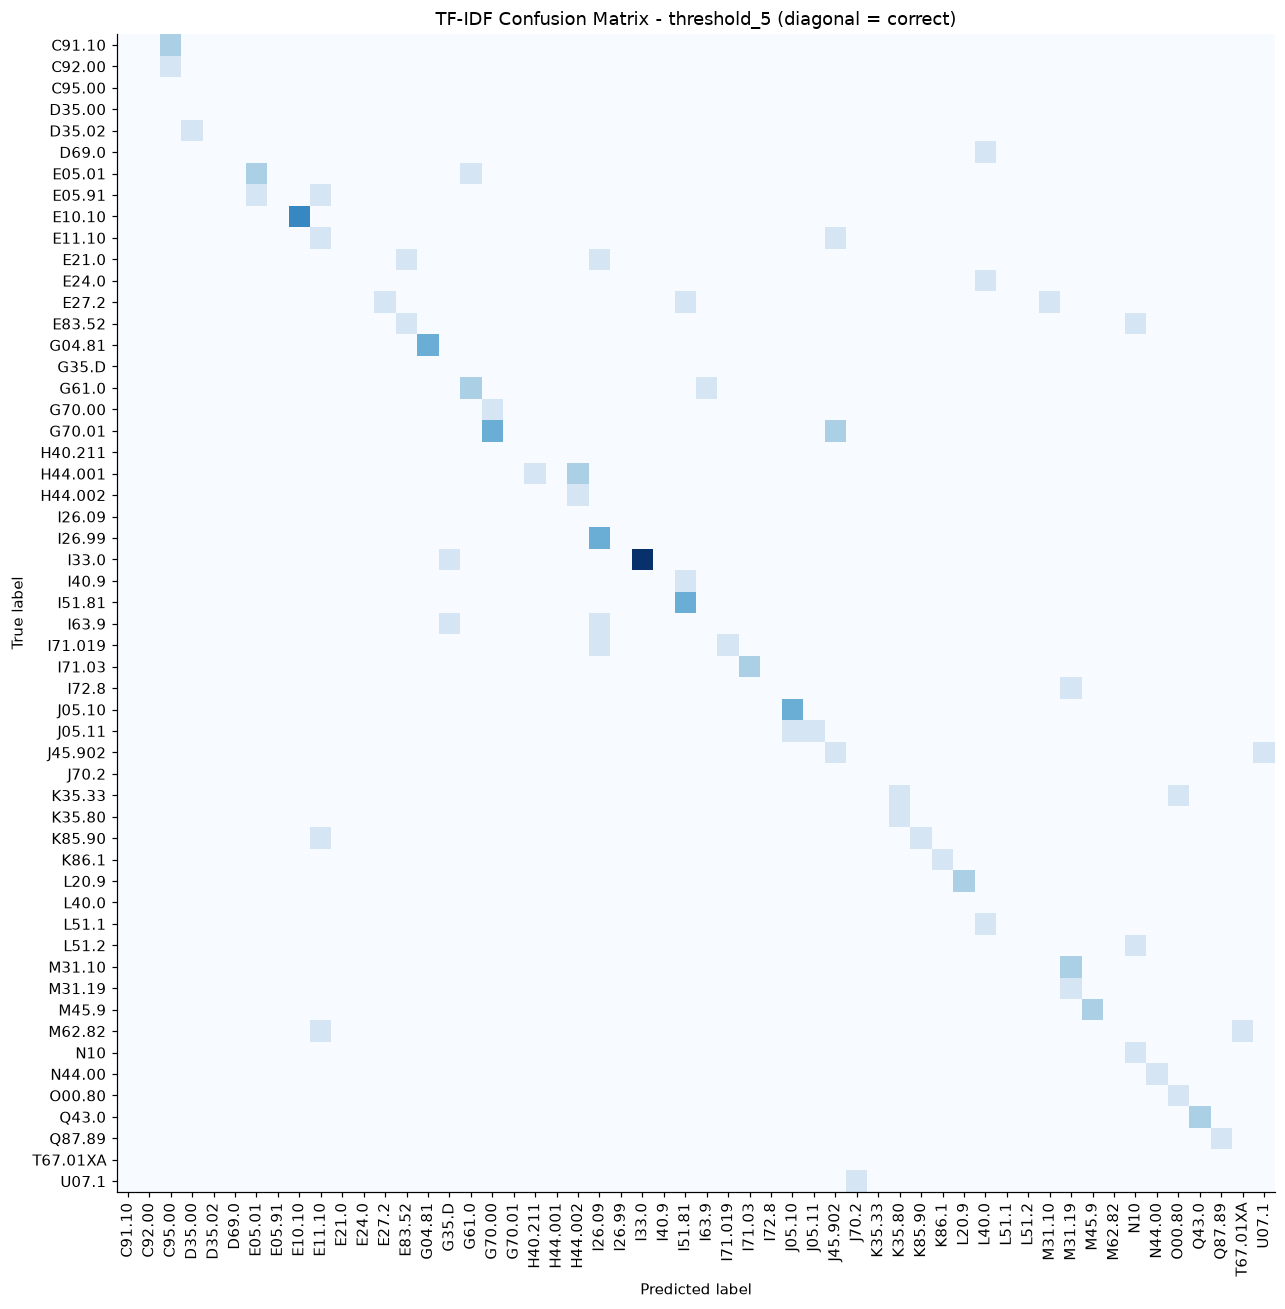

In [20]:
# ==========================================
# DETAILED TF-IDF EVALUATION
# ==========================================

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

for experiment_name, split_data in splits.items():

    print("\n" + "=" * 65)
    print(f"DETAILED EVALUATION: {experiment_name}")
    print("=" * 65)

    y_test = split_data["y_test"]
    y_pred = predictions[("TF-IDF + LR", experiment_name)]

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    labels = sorted(set(y_test).union(set(y_pred)))
    cm = confusion_matrix(y_test, y_pred, labels=labels)

    fig, ax = plt.subplots(figsize=(14, 12))
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(
        ax=ax, xticks_rotation=90, colorbar=False, cmap="Blues", include_values=False
    )
    ax.set_title(f"TF-IDF Confusion Matrix - {experiment_name} (diagonal = correct)")
    ax.grid(False)
    plt.tight_layout()
    plt.savefig(f"figures/confusion_tfidf_{experiment_name}.png", bbox_inches="tight")
    plt.show()

## 7. Model 2: Sentence Embeddings + Logistic Regression

```
Clinical narrative -> pretrained sentence transformer -> dense vector -> Logistic Regression -> ICD-10 code
```

We compare two English encoders:

| Encoder | Why | Max input length |
|---|---|---|
| `sentence-transformers/all-MiniLM-L6-v2` | Small, fast, popular general-purpose model (the original choice) | 256 tokens |
| `NeuML/pubmedbert-base-embeddings` | PubMedBERT fine-tuned as a sentence encoder on PubMed text: same domain as our PubMed Central case reports | 512 tokens |

The encoders are used frozen (no fine-tuning). Each note is embedded independently, so embedding all notes up front leaks nothing; the Logistic Regression is trained on training embeddings only, with `C` tuned by the same grouped cross-validation.

First we check how much of each note each encoder can actually read.

In [21]:
# ==========================================
# GENERATE SENTENCE EMBEDDINGS
# ==========================================

from sentence_transformers import SentenceTransformer
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()  # silence "sequence longer than max length" notices

EMBEDDING_MODELS = {
    "MiniLM + LR": "sentence-transformers/all-MiniLM-L6-v2",
    "PubMedBERT + LR": "NeuML/pubmedbert-base-embeddings",
}

# The >= 4 experiment contains every note used by either experiment
all_notes = experiments["threshold_4"]["clean_input"].tolist()

encoders, note_embeddings, truncation_rows = {}, {}, []

for model_name, model_id in EMBEDDING_MODELS.items():
    encoder = SentenceTransformer(model_id)
    n_tokens = np.array([len(encoder.tokenizer(note)["input_ids"]) for note in all_notes])

    truncation_rows.append({
        "Encoder": model_id,
        "Max tokens": encoder.max_seq_length,
        "Median note tokens": int(np.median(n_tokens)),
        "Notes truncated (%)": round((n_tokens > encoder.max_seq_length).mean() * 100, 1),
    })

    vectors = encoder.encode(all_notes, batch_size=32, show_progress_bar=True, normalize_embeddings=True)
    encoders[model_name] = encoder
    note_embeddings[model_name] = dict(zip(all_notes, vectors))

display(pd.DataFrame(truncation_rows))


def embed(notes, model_name):
    """Look up the pre-computed embedding of each note."""
    return np.vstack([note_embeddings[model_name][note] for note in notes])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 10083.87it/s]

Batches:   0%|          | 0/20 [00:00<?, ?it/s]

Batches:   5%|▌         | 1/20 [00:00<00:12,  1.49it/s]

Batches:  15%|█▌        | 3/20 [00:00<00:04,  4.07it/s]

...

Batches:  85%|████████▌ | 17/20 [00:15<00:02,  1.19it/s]

Batches:  90%|█████████ | 18/20 [00:16<00:01,  1.27it/s]

Batches:  95%|█████████▌| 19/20 [00:16<00:00,  1.30it/s]

Batches: 100%|██████████| 20/20 [00:16<00:00,  1.18it/s]

,Encoder,Max tokens,Median note tokens,Notes truncated (%)
0,sentence-transformers/all-MiniLM-L6-v2,256,351,94.6
1,NeuML/pubmedbert-base-embeddings,512,293,0.0


**Important finding.** MiniLM can only read the first 256 tokens, which truncates nearly every note: the end of a case report (investigations, final diagnosis) is never seen. PubMedBERT reads up to 512 tokens and sees every note in full, and its vocabulary is medical, so clinical terms are split into far fewer sub-word tokens.

In [22]:
# ==========================================
# MODEL 2: EMBEDDINGS + LOGISTIC REGRESSION
# ==========================================

for model_name in EMBEDDING_MODELS:
    for experiment_name, split_data in splits.items():

        X_train = embed(split_data["X_train"], model_name)
        X_test = embed(split_data["X_test"], model_name)

        search = GridSearchCV(
            LogisticRegression(max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE),
            {"C": [1, 10, 100]},
            cv=tuning_cv,
            scoring="accuracy",
            n_jobs=-1,
        )
        search.fit(X_train, split_data["y_train"], groups=split_data["groups_train"])

        record(model_name, experiment_name, search.best_estimator_, X_test, split_data["y_test"], search)
        print("   best parameters:", search.best_params_, "| embedding size:", X_train.shape[1])

MiniLM + LR      | threshold_4: accuracy 0.2927 | top-5 0.6829 | macro F1 0.2113 | weighted F1 0.2872
   best parameters: {'C': 10} | embedding size: 384


MiniLM + LR      | threshold_5: accuracy 0.4457 | top-5 0.8152 | macro F1 0.3807 | weighted F1 0.4256
   best parameters: {'C': 10} | embedding size: 384


PubMedBERT + LR  | threshold_4: accuracy 0.4472 | top-5 0.8211 | macro F1 0.2961 | weighted F1 0.4378
   best parameters: {'C': 10} | embedding size: 768


PubMedBERT + LR  | threshold_5: accuracy 0.6087 | top-5 0.9022 | macro F1 0.4940 | weighted F1 0.5922
   best parameters: {'C': 10} | embedding size: 768


### 7.1 Detailed evaluation of the biomedical embedding model

In [23]:
# ==========================================
# EMBEDDING MODEL DETAILED EVALUATION
# ==========================================

for experiment_name, split_data in splits.items():
    print("\n" + "=" * 65)
    print(f"PUBMEDBERT EVALUATION: {experiment_name}")
    print("=" * 65)
    print(classification_report(
        split_data["y_test"], predictions[("PubMedBERT + LR", experiment_name)], zero_division=0
    ))


PUBMEDBERT EVALUATION: threshold_4
              precision    recall  f1-score   support

       A15.0       0.00      0.00      0.00         1
      B44.81       0.00      0.00      0.00         0
      C34.32       0.00      0.00      0.00         0
      C83.30       0.00      0.00      0.00         1
      C91.10       0.00      0.00      0.00         1
      C92.00       0.00      0.00      0.00         1
      C95.00       1.00      0.50      0.67         4
      D35.00       0.00      0.00      0.00         3
      D35.01       0.00      0.00      0.00         0
      D35.02       0.50      0.50      0.50         2
         D65       0.00      0.00      0.00         1
       D69.0       0.50      0.50      0.50         2
      E05.01       0.71      0.83      0.77         6
      E05.30       0.00      0.00      0.00         1
      E05.91       0.00      0.00      0.00         1
      E10.10       0.33      0.50      0.40         2
      E11.10       0.00      0.00      0.00  

### Hyperparameters selected by grouped cross-validation (training data only)

In [24]:
display(pd.DataFrame(tuning))

,Model,Dataset,Best parameters,CV accuracy (train only)
0,TF-IDF + LR,threshold_4,"{'clf__C': 10, 'tfidf__min_df': 1, 'tfidf__ngr...",0.4233
1,TF-IDF + LR,threshold_5,"{'clf__C': 1, 'tfidf__min_df': 1, 'tfidf__ngra...",0.5870
2,MiniLM + LR,threshold_4,{'C': 10},0.3047
3,MiniLM + LR,threshold_5,{'C': 10},0.4212
4,PubMedBERT + LR,threshold_4,{'C': 10},0.3926
5,PubMedBERT + LR,threshold_5,{'C': 10},0.5353


## 8. Evaluation and Model Comparison

All models are evaluated on the same untouched test sets with the same metrics. A **majority-class baseline** (always predict the most frequent training code; for top-k, the k most frequent codes) shows what "no learning" scores.

- **Accuracy** - share of notes whose top prediction is the correct code
- **Top-3 / Top-5 accuracy** - correct code is among the 3 / 5 highest-probability suggestions (realistic for a coding *assistant* that proposes candidates)
- **Macro F1** - F1 per class averaged with equal weight (sensitive to rare classes)
- **Weighted F1 / precision / recall** - averaged by class support

In [25]:
# ==========================================
# FINAL MODEL COMPARISON + BASELINE
# ==========================================

MODEL_ORDER = ["Majority baseline", "TF-IDF + LR", "MiniLM + LR", "PubMedBERT + LR"]
DATASET_LABELS = {"threshold_4": ">= 4 cases (96 classes)", "threshold_5": ">= 5 cases (58 classes)"}

for experiment_name, split_data in splits.items():
    y_train, y_test = split_data["y_train"], split_data["y_test"]

    # Baseline ranks codes by training frequency, ignoring the note entirely
    classes = np.array(sorted(y_train.unique()))
    class_freq = y_train.value_counts().reindex(classes).values / len(y_train)
    proba = np.tile(class_freq, (len(y_test), 1))
    y_pred = classes[proba.argmax(axis=1)]

    key = ("Majority baseline", experiment_name)
    predictions[key], probabilities[key] = y_pred, proba
    results[key] = evaluate(y_test, y_pred, proba, classes)

comparison_df = pd.DataFrame([
    {"Dataset": DATASET_LABELS[d], "Model": m, **results[(m, d)]}
    for d in splits for m in MODEL_ORDER
])

comparison_display = comparison_df.rename(columns={
    "accuracy": "Accuracy", "top3_accuracy": "Top-3 Acc", "top5_accuracy": "Top-5 Acc",
    "macro_precision": "Macro Precision", "macro_recall": "Macro Recall", "macro_f1": "Macro F1",
    "weighted_precision": "Weighted Precision", "weighted_recall": "Weighted Recall", "weighted_f1": "Weighted F1",
})
metric_columns = comparison_display.columns[2:]
comparison_display[metric_columns] = (comparison_display[metric_columns] * 100).round(2)

print("FINAL MODEL PERFORMANCE COMPARISON (%)")
display(comparison_display)

FINAL MODEL PERFORMANCE COMPARISON (%)


,Dataset,Model,Accuracy,Top-3 Acc,Top-5 Acc,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1
0,>= 4 cases (96 classes),Majority baseline,5.69,8.13,17.07,0.08,1.49,0.16,0.32,5.69,0.61
1,>= 4 cases (96 classes),TF-IDF + LR,39.02,64.23,72.36,25.78,29.37,25.24,36.11,39.02,33.64
2,>= 4 cases (96 classes),MiniLM + LR,29.27,60.16,68.29,21.83,23.71,21.13,33.02,29.27,28.72
3,>= 4 cases (96 classes),PubMedBERT + LR,44.72,72.36,82.11,31.04,31.70,29.61,48.34,44.72,43.78
4,>= 5 cases (58 classes),Majority baseline,7.61,14.13,16.30,0.17,2.17,0.31,0.58,7.61,1.08
5,>= 5 cases (58 classes),TF-IDF + LR,51.09,79.35,85.87,36.76,41.71,36.41,50.24,51.09,48.10
6,>= 5 cases (58 classes),MiniLM + LR,44.57,71.74,81.52,39.38,42.87,38.07,46.32,44.57,42.56
7,>= 5 cases (58 classes),PubMedBERT + LR,60.87,84.78,90.22,53.26,52.92,49.40,65.70,60.87,59.22


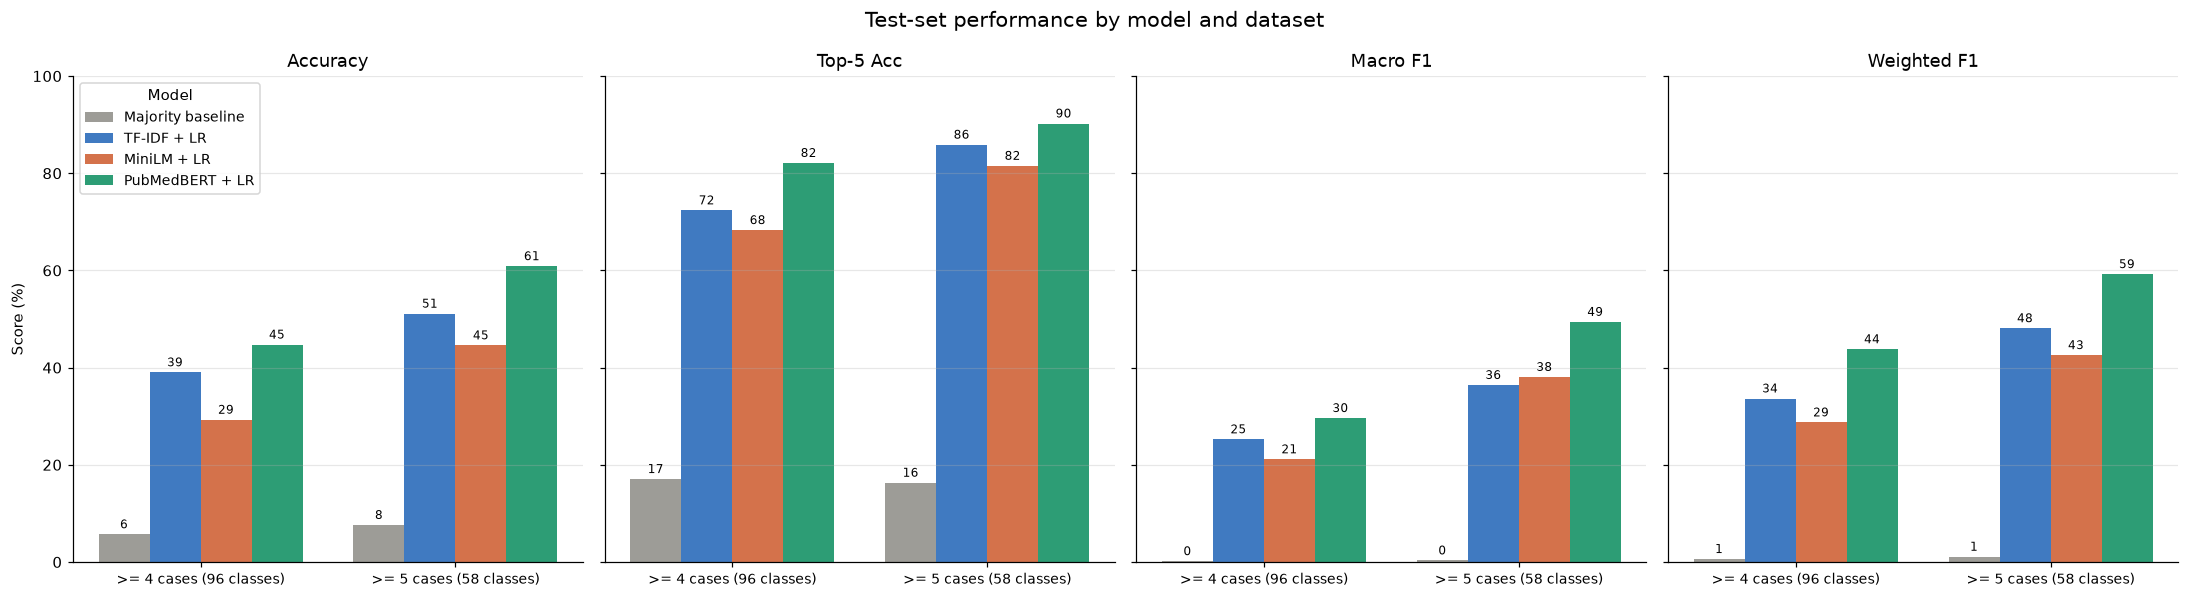

In [26]:
# ==========================================
# MODEL PERFORMANCE VISUALIZATION
# ==========================================

plot_df = comparison_display.melt(
    id_vars=["Dataset", "Model"],
    value_vars=["Accuracy", "Top-5 Acc", "Macro F1", "Weighted F1"],
    var_name="Metric", value_name="Score (%)",
)

fig, axes = plt.subplots(1, 4, figsize=(20, 5.5), sharey=True)
for ax, metric in zip(axes, ["Accuracy", "Top-5 Acc", "Macro F1", "Weighted F1"]):
    sns.barplot(
        data=plot_df[plot_df["Metric"] == metric], x="Dataset", y="Score (%)",
        hue="Model", hue_order=MODEL_ORDER, palette=MODEL_COLORS, ax=ax, width=0.8,
    )
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", fontsize=8, padding=2)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", labelsize=9)
    if ax is not axes[0]:
        ax.get_legend().remove()
axes[0].legend(title="Model", loc="upper left", fontsize=9)

plt.suptitle("Test-set performance by model and dataset", fontsize=14)
plt.tight_layout()
plt.savefig("figures/model_comparison.png", bbox_inches="tight")
plt.show()

### 8.3 Robustness check: 5-fold grouped cross-validation

With only 92-123 test notes, a single split is noisy (one note = about 1 percentage point). To check whether the ranking of models is real or luck, each model (with the hyperparameters chosen above) is re-trained and evaluated with **5-fold publication-grouped cross-validation, repeated with 3 different shuffles (15 train/test rounds per model)** over the whole dataset. This is a variance check, not a second round of tuning.

,Dataset,Model,Accuracy mean (%),Accuracy std (%),Macro F1 mean (%),Macro F1 std (%)
0,>= 4 cases (96 classes),TF-IDF + LR,47.76,3.08,31.37,2.61
1,>= 4 cases (96 classes),MiniLM + LR,35.40,2.58,25.02,2.75
2,>= 4 cases (96 classes),PubMedBERT + LR,44.87,3.11,34.02,3.60
3,>= 5 cases (58 classes),TF-IDF + LR,62.09,5.28,53.15,5.49
4,>= 5 cases (58 classes),MiniLM + LR,45.89,4.61,38.82,4.00
5,>= 5 cases (58 classes),PubMedBERT + LR,56.38,4.64,48.20,4.52


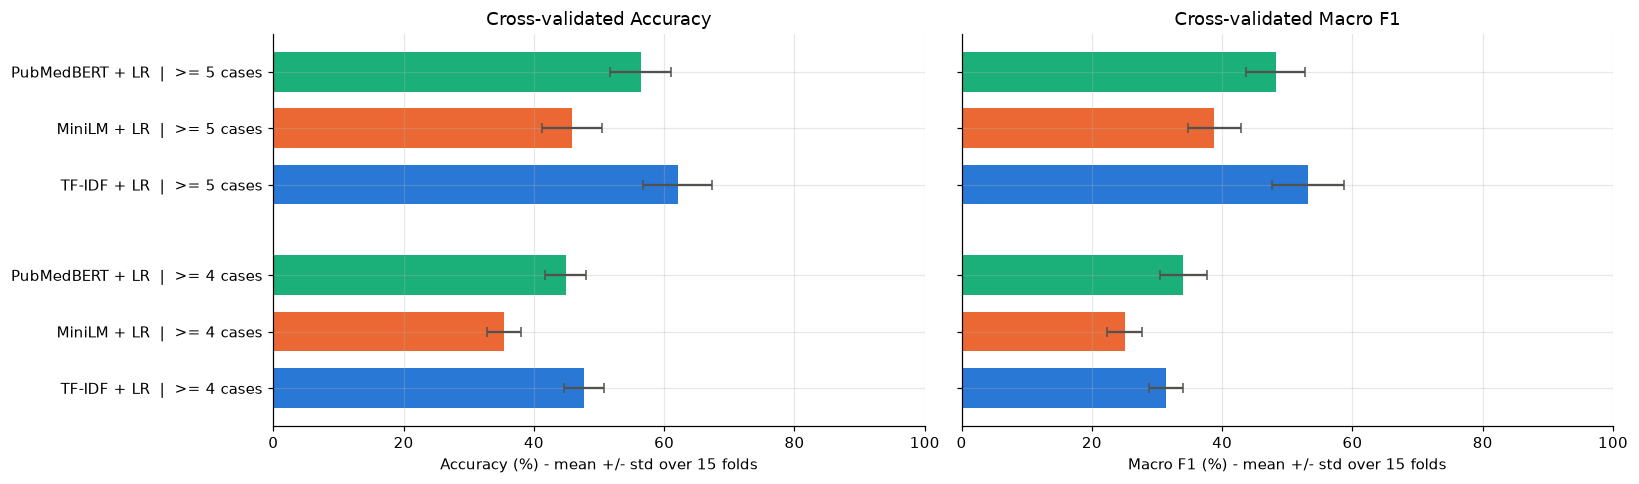

In [27]:
# ==========================================
# 5-FOLD GROUPED CROSS-VALIDATION
# ==========================================

from sklearn.base import clone
from sklearn.model_selection import cross_validate

CV_SEEDS = [0, 1, 2]
robust_rows = []

for experiment_name, data in experiments.items():
    y, groups = data["icd10_code"], data["split_group"]
    inputs = {"TF-IDF + LR": data["clean_input"]}
    inputs.update({m: embed(data["clean_input"], m) for m in EMBEDDING_MODELS})

    for model_name, X in inputs.items():
        accuracy, macro_f1 = [], []
        for seed in CV_SEEDS:
            scores = cross_validate(
                clone(fitted[(model_name, experiment_name)]), X, y, groups=groups,
                cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed),
                scoring=["accuracy", "f1_macro"], n_jobs=-1,
            )
            accuracy += list(scores["test_accuracy"])
            macro_f1 += list(scores["test_f1_macro"])
        robust_rows.append({
            "Dataset": DATASET_LABELS[experiment_name],
            "Model": model_name,
            "Accuracy mean (%)": round(np.mean(accuracy) * 100, 2),
            "Accuracy std (%)": round(np.std(accuracy) * 100, 2),
            "Macro F1 mean (%)": round(np.mean(macro_f1) * 100, 2),
            "Macro F1 std (%)": round(np.std(macro_f1) * 100, 2),
        })

robust_df = pd.DataFrame(robust_rows)
display(robust_df)

positions = [row + (row // 3) * 0.6 for row in range(len(robust_df))]  # gap between datasets
labels = [f"{r['Model']}  |  {r['Dataset'].split(' (')[0]}" for _, r in robust_df.iterrows()]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, metric in zip(axes, ["Accuracy", "Macro F1"]):
    ax.barh(positions, robust_df[f"{metric} mean (%)"], xerr=robust_df[f"{metric} std (%)"], height=0.7,
            color=[MODEL_COLORS[m] for m in robust_df["Model"]], error_kw={"ecolor": "#52514e", "capsize": 3})
    ax.set_yticks(positions, labels)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel(f"{metric} (%) - mean +/- std over 15 folds")
    ax.set_title(f"Cross-validated {metric}")
plt.tight_layout()
plt.savefig("figures/cross_validation.png", bbox_inches="tight")
plt.show()

### 8.4 Combining the two models (rank fusion)

TF-IDF and PubMedBERT are right on partly different notes (see Section 10.3), so we combine them with **reciprocal rank fusion**. No extra training is involved. Each model gives every code the score 1 / (k + rank), and the two scores are added. With k = 1, a code both models rank first gets the maximum score (shown as "consensus 100%" in the web app). Ties go to the code PubMedBERT is more confident about.

We also measure how much to trust the two models when they **agree**, since that tells a coder which notes need a closer look.

In [28]:
# ==========================================
# 8.4 RANK FUSION OF TF-IDF AND PUBMEDBERT
# ==========================================

RRF_K = 1  # k=60 (the textbook value) gives the same accuracy but squeezes the scores together


def rank_fusion(proba_tfidf, proba_emb):
    rank_t = (-proba_tfidf).argsort(axis=1).argsort(axis=1) + 1
    rank_e = (-proba_emb).argsort(axis=1).argsort(axis=1) + 1
    return 1 / (RRF_K + rank_t) + 1 / (RRF_K + rank_e) + 1e-6 * proba_emb  # tie-break: PubMedBERT confidence


fusion_rows = []
for experiment_name, split_data in splits.items():
    y_test = split_data["y_test"].to_numpy()
    classes = fitted[("TF-IDF + LR", experiment_name)].classes_
    p_t = probabilities[("TF-IDF + LR", experiment_name)]
    p_e = probabilities[("PubMedBERT + LR", experiment_name)]
    hits = classes[np.argsort(-rank_fusion(p_t, p_e), axis=1)] == y_test[:, None]

    # same repeated grouped CV as Section 8.3
    data = experiments[experiment_name]
    y, groups = data["icd10_code"], data["split_group"]
    X_emb = embed(data["clean_input"], "PubMedBERT + LR")
    cv_accuracy = []
    for seed in CV_SEEDS:
        for tr, te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed).split(X_emb, y, groups):
            t = clone(fitted[("TF-IDF + LR", experiment_name)]).fit(data["clean_input"].iloc[tr], y.iloc[tr])
            e = clone(fitted[("PubMedBERT + LR", experiment_name)]).fit(X_emb[tr], y.iloc[tr])
            fused = rank_fusion(t.predict_proba(data["clean_input"].iloc[te]), e.predict_proba(X_emb[te]))
            cv_accuracy.append((t.classes_[fused.argmax(axis=1)] == y.iloc[te].to_numpy()).mean())

    # agreement between the two models on the test set
    top_t, top_e = classes[p_t.argmax(axis=1)], classes[p_e.argmax(axis=1)]
    agree = top_t == top_e
    fusion_top = classes[rank_fusion(p_t, p_e).argmax(axis=1)]

    for model_name in ["TF-IDF + LR", "PubMedBERT + LR", "Combined (rank fusion)"]:
        if model_name == "Combined (rank fusion)":
            test_acc, top5, cv_mean, cv_std = hits[:, 0].mean(), hits[:, :5].any(axis=1).mean(), np.mean(cv_accuracy), np.std(cv_accuracy)
        else:
            r = robust_df[(robust_df["Dataset"] == DATASET_LABELS[experiment_name]) & (robust_df["Model"] == model_name)].iloc[0]
            test_acc, top5 = results[(model_name, experiment_name)]["accuracy"], results[(model_name, experiment_name)]["top5_accuracy"]
            cv_mean, cv_std = r["Accuracy mean (%)"] / 100, r["Accuracy std (%)"] / 100
        fusion_rows.append({
            "Dataset": DATASET_LABELS[experiment_name], "Model": model_name,
            "Test accuracy (%)": round(test_acc * 100, 2), "Test top-5 (%)": round(top5 * 100, 2),
            "CV accuracy mean (%)": round(cv_mean * 100, 2), "CV accuracy std (%)": round(cv_std * 100, 2),
        })

    print(f"{DATASET_LABELS[experiment_name]}: models agree on {agree.mean() * 100:.1f}% of test notes; "
          f"accuracy when they agree {(top_t[agree] == y_test[agree]).mean() * 100:.1f}%, "
          f"combined accuracy when they disagree {(fusion_top[~agree] == y_test[~agree]).mean() * 100:.1f}%")

fusion_df = pd.DataFrame(fusion_rows)
display(fusion_df)
fusion_df.to_csv("fusion_results.csv", index=False)

>= 4 cases (96 classes): models agree on 49.6% of test notes; accuracy when they agree 57.4%, combined accuracy when they disagree 30.6%


>= 5 cases (58 classes): models agree on 58.7% of test notes; accuracy when they agree 72.2%, combined accuracy when they disagree 50.0%


,Dataset,Model,Test accuracy (%),Test top-5 (%),CV accuracy mean (%),CV accuracy std (%)
0,>= 4 cases (96 classes),TF-IDF + LR,39.02,72.36,47.76,3.08
1,>= 4 cases (96 classes),PubMedBERT + LR,44.72,82.11,44.87,3.11
2,>= 4 cases (96 classes),Combined (rank fusion),43.90,78.86,49.28,2.87
3,>= 5 cases (58 classes),TF-IDF + LR,51.09,85.87,62.09,5.28
4,>= 5 cases (58 classes),PubMedBERT + LR,60.87,90.22,56.38,4.64
5,>= 5 cases (58 classes),Combined (rank fusion),63.04,91.30,61.02,3.99


**Result.** The combined model is the most consistent of the three. It has the best test accuracy and top-5 accuracy on the >= 5 experiment (63.0%, 91.3%) and the best cross-validated accuracy on the harder >= 4 experiment (49.3%). Elsewhere it is within about 1 point of the best model, and it has the smallest spread across folds in both experiments. It does not need to know in advance which single model suits a dataset. Agreement is a useful warning signal: when the two models pick the same code they are right far more often than when they disagree, so disagreements can be routed to a human coder. The Chart2Code web app (Section 14) uses exactly this combined model.

## 9. Explainability

Three complementary views:

1. **Global (TF-IDF):** which words push the model towards each ICD-10 code (Logistic Regression coefficients).
2. **Local (TF-IDF):** for one note, which of its words contributed most to the prediction, plus the top-5 codes with their probabilities.
3. **Example-based (embeddings):** dense vectors are not directly interpretable, so we show the most similar training cases the embedding model is "reasoning from".

Probabilities are **model confidence estimates**, not clinical certainty.

In [29]:
# ==========================================
# 9.1 MOST INFLUENTIAL WORDS PER ICD-10 CODE (TF-IDF)
# ==========================================

PRIMARY = "threshold_5"
tfidf_model = fitted[("TF-IDF + LR", PRIMARY)]
vectorizer = tfidf_model.named_steps["tfidf"]
tfidf_clf = tfidf_model.named_steps["clf"]
feature_names = vectorizer.get_feature_names_out()

top_codes = splits[PRIMARY]["y_train"].value_counts().head(10).index

rows = []
for code_ in top_codes:
    class_idx = list(tfidf_clf.classes_).index(code_)
    top_features = np.argsort(tfidf_clf.coef_[class_idx])[::-1][:10]
    rows.append({
        "ICD-10": code_,
        "Diagnosis": code_to_diagnosis[code_],
        "Most influential words / phrases": ", ".join(feature_names[top_features]),
    })

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows))

,ICD-10,Diagnosis,Most influential words / phrases
0,I33.0,Acute and subacute infective endocarditis,"valve, blood cultures, cultures, mitral, aortic, aortic valve, mobile, regurgitation, murmur, echocardiography"
1,E05.01,Thyrotoxicosis with diffuse goiter with thyrotoxic crisis or storm,"thyroid, tachycardia, elevated free, free, antithyroid, antithyroid medication, suppressed, free t4, t4, tsh"
2,G04.81,Other encephalitis and encephalomyelitis,"eeg, seizures, eeg showed, mri, slowing, memory, brain mri, cranial, cerebrospinal, cerebrospinal fluid"
3,I71.019,"Dissection of thoracic aorta, unspecified","aortic, aorta, ascending aorta, ascending, aortic root, root, was obtained, chest, aortic regurgitation, severe aortic"
4,I26.09,Other pulmonary embolism with acute cor pulmonale,"right ventricular, ng ml, pulmonary artery, ml, pulmonary, oxygen, showed sinus, ng, dimer, right"
5,G61.0,Guillain-Barre syndrome,"weakness, limbs, reflexes, absent, limb, motor, nerve, limb weakness, elevated protein, sensory"
6,I71.03,Dissection of thoracoabdominal aorta,"aortic, aorta, arch, flap, iliac, malperfusion, the aortic, arteries, down, enhanced computed"
7,N10,Acute pyelonephritis,"perirenal, kidney, gas, flank, costovertebral, costovertebral angle, tenderness, renal, was seen, urinalysis showed"
8,E10.10,Type 1 diabetes mellitus with ketoacidosis without coma,"insulin, bicarbonate, glucose, blood glucose, mmol, gap, anion gap, anion, meq, diabetes"
9,O00.80,Other ectopic pregnancy without intrauterine pregnancy,"pregnancy, hcg, vaginal, bleeding, vaginal bleeding, sac, adnexal, uterine, hcg was, intrauterine"


The learned words are clinically sensible even though the diagnosis itself is never written in the notes: endocarditis is recognised from *blood cultures, valve, murmur, regurgitation, echocardiography*; thyroid storm from *thyroid, tachycardia, free T4, TSH, antithyroid medication*; diabetic ketoacidosis from *insulin, bicarbonate, glucose, anion gap*; ectopic pregnancy from *hCG, vaginal bleeding, adnexal*; pyelonephritis from *flank, costovertebral angle tenderness, perirenal*. The model is learning findings a clinician would use, not artefacts.

CORRECT PREDICTION | true code: J05.11 (Acute epiglottitis with obstruction)
A man in his late 60s with a recently diagnosed advanced-stage (locally advanced, node-positive, non-metastatic) squamous cell carcinoma of the posterior oropharyngeal wall—radiotherapy for which had been delayed pending dental clearance and due to inability to lie flat without desaturation—presented to the emergency department with throat pain and difficulty swallowing. His oncology team had raised concern for possible airway compromise. Initial physical exam revealed a visible oropharyngeal mass raising concern for airway narrowing. CT of the neck showed an increase in size of the known pharyngeal mass with moderate narrowing of the oropharyngeal airway compared with prior imaging. Shortly ...



,ICD-10,Diagnosis,Model confidence
0,J05.11,Acute epiglottitis with obstruction,0.024
1,J05.10,Acute epiglottitis without obstruction,0.022
2,G70.01,Myasthenia gravis with (acute) exacerbation,0.018
3,I71.019,"Dissection of thoracic aorta, unspecified",0.018
4,C34.32,"Malignant neoplasm of lower lobe, left bronchu...",0.018


INCORRECT PREDICTION | true code: E21.0 (Primary hyperparathyroidism)
An adult man in his late 30s presented with a three-day history of severe abdominal pain associated with nausea and vomiting. On examination he was hemodynamically stable but mildly tachycardic (heart rate 105 bpm). The abdomen was distended with epigastric tenderness, guarding, and absent bowel sounds. No significant past medical history was reported. Initial blood tests showed hemoglobin 132 g/L, white cell count 6.2 x10^9/L, platelets 355 x10^9/L, neutrophils 6.3 x10^9/L, C-reactive protein markedly elevated at 108 mg/L, and amylase mildly elevated at 117 U/L. Renal function was normal (urea 2.5 mmol/L, creatinine 75 umol/L, sodium 136 mmol/L, potassium 4.3 mmol/L). Serum calcium was elev ...



,ICD-10,Diagnosis,Model confidence
0,E83.52,Hypercalcemia,0.021
1,K35.33,"Acute appendicitis with perforation, localized...",0.020
2,Q43.0,Meckel's diverticulum (displaced) (hypertrophic),0.020
3,I72.8,Aneurysm of other specified arteries,0.020
4,K35.80,Unspecified acute appendicitis,0.019


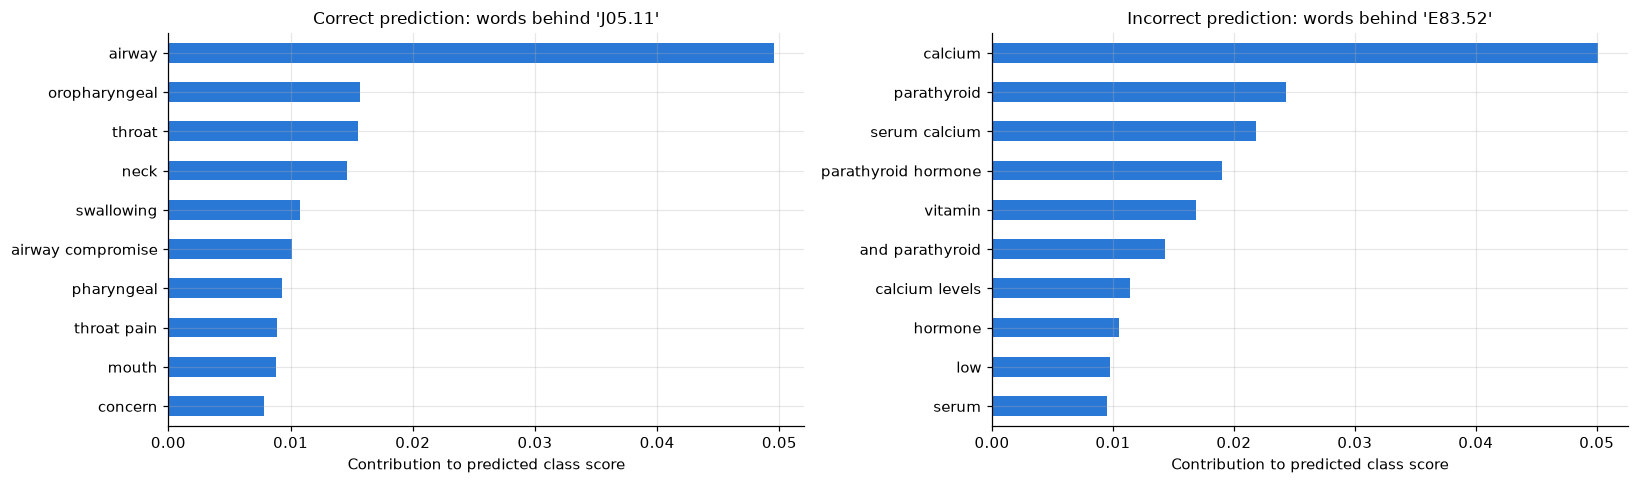

In [30]:
# ==========================================
# 9.2 EXPLAIN INDIVIDUAL PREDICTIONS (TF-IDF)
# ==========================================

def explain_tfidf(note, model=tfidf_model, k=5, top_words=10):
    """Top-k codes with probabilities, and the words that drove the top prediction."""
    vec, clf = model.named_steps["tfidf"], model.named_steps["clf"]
    x = vec.transform([clean_text(note)])
    proba = clf.predict_proba(x)[0]
    top = np.argsort(proba)[::-1][:k]

    top_k = pd.DataFrame({
        "ICD-10": clf.classes_[top],
        "Diagnosis": code_to_diagnosis.reindex(clf.classes_[top]).values,
        "Model confidence": proba[top].round(3),
    })

    # Contribution of each word = its TF-IDF value x its coefficient for the predicted class
    contributions = x.toarray()[0] * clf.coef_[top[0]]
    order = np.argsort(contributions)[::-1][:top_words]
    words = pd.Series(contributions[order], index=vec.get_feature_names_out()[order])
    return top_k, words[words > 0]


test_notes = splits[PRIMARY]["X_test"].reset_index(drop=True)
test_labels = splits[PRIMARY]["y_test"].reset_index(drop=True)
tfidf_test_pred = pd.Series(predictions[("TF-IDF + LR", PRIMARY)])

examples = {
    "Correct prediction": int(np.flatnonzero(tfidf_test_pred == test_labels)[0]),
    "Incorrect prediction": int(np.flatnonzero(tfidf_test_pred != test_labels)[0]),
}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (title, i) in zip(axes, examples.items()):
    top_k, words = explain_tfidf(test_notes[i])
    print("=" * 90)
    print(f"{title.upper()} | true code: {test_labels[i]} ({code_to_diagnosis[test_labels[i]]})")
    print("=" * 90)
    print(test_notes[i][:700], "...\n")
    display(top_k)

    words[::-1].plot.barh(ax=ax, color=MODEL_COLORS["TF-IDF + LR"])
    ax.set_title(f"{title}: words behind '{top_k['ICD-10'][0]}'", fontsize=11)
    ax.set_xlabel("Contribution to predicted class score")

plt.tight_layout()
plt.savefig("figures/tfidf_word_explanations.png", bbox_inches="tight")
plt.show()

*Note on confidence values:* the tuned TF-IDF model uses strong regularisation, so its probabilities are almost flat (about 0.02 each across 58 codes). Its **ranking** is useful (top-5 accuracy above 85%) but its absolute probabilities are not. The PubMedBERT model produces far more informative confidence values (see the demo in Section 11).

In [31]:
# ==========================================
# 9.3 EXAMPLE-BASED EXPLANATION (EMBEDDINGS)
# ==========================================

def similar_training_cases(note, model_name="PubMedBERT + LR", experiment_name=PRIMARY, n=3):
    """Training cases closest to a note in embedding space (cosine similarity)."""
    train_notes = splits[experiment_name]["X_train"].reset_index(drop=True)
    train_labels = splits[experiment_name]["y_train"].reset_index(drop=True)
    query = encoders[model_name].encode([clean_text(note)], normalize_embeddings=True)
    similarity = embed(train_notes, model_name) @ query[0]
    nearest = np.argsort(similarity)[::-1][:n]
    return pd.DataFrame({
        "Similarity": similarity[nearest].round(3),
        "ICD-10": train_labels[nearest].values,
        "Diagnosis": code_to_diagnosis.reindex(train_labels[nearest]).values,
        "Training note (start)": train_notes[nearest].str[:160].values + "...",
    })


pubmed_test_pred = pd.Series(predictions[("PubMedBERT + LR", PRIMARY)])
i = int(np.flatnonzero(pubmed_test_pred != test_labels)[0])  # first PubMedBERT error
pubmed_pred = pubmed_test_pred[i]
print(f"Test note true code: {test_labels[i]} ({code_to_diagnosis[test_labels[i]]})")
print(f"PubMedBERT prediction: {pubmed_pred} ({code_to_diagnosis[pubmed_pred]})\n")
print(test_notes[i][:500], "...\n")
print("Most similar training cases:")
with pd.option_context("display.max_colwidth", None):
    display(similar_training_cases(test_notes[i]))

Test note true code: E10.10 (Type 1 diabetes mellitus with ketoacidosis without coma)
PubMedBERT prediction: K85.90 (Acute pancreatitis without necrosis or infection, unspecified)

A woman in her early 40s presented to the emergency department with a 3-day history of upper abdominal pain, nausea, and vomiting. She had no known history of diabetes mellitus or prior abnormal urine glucose testing. She weighed 45 kg (BMI 19 kg/m2). On arrival she was mildly disoriented with tachypnea (respiratory rate 34/min), dry oral mucosa, and mild tenderness from the epigastrium to the right hypochondrium; Murphy's sign was negative, and there were no peritoneal signs. Initial labs showe ...

Most similar training cases:


,Similarity,ICD-10,Diagnosis,Training note (start)
0,0.804,K85.90,"Acute pancreatitis without necrosis or infection, unspecified","A man in his late 20s presented to the emergency department with acute-onset abdominal pain and vomiting. The pain was constant, severe (9/10), located in the e..."
1,0.800,K86.1,Other chronic pancreatitis,"A man in his early 60s presented to the emergency department with a four-day history of abdominal pain radiating to the lower back, accompanied by nausea, vomit..."
2,0.794,E21.0,Primary hyperparathyroidism,"A woman in her late 50s presented to the emergency department with a 4-day history of sharp, unremitting left upper quadrant abdominal pain radiating to the bac..."


## 10. Error Analysis

Questions: how wrong are the wrong predictions, which codes get confused, do the two model families make the same mistakes, and how do rare classes fare?

ICD-10 codes are hierarchical: `E05.01` = chapter **E** (endocrine) -> category **E05** (thyrotoxicosis) -> full code. An error inside the same 3-character category is a "near miss" (right disease, wrong detail).

In [32]:
# ==========================================
# 10.1 HOW CLOSE ARE THE ERRORS? (ICD-10 HIERARCHY)
# ==========================================

hierarchy_rows = []
for experiment_name, split_data in splits.items():
    y_test = split_data["y_test"].reset_index(drop=True)
    for model_name in MODEL_ORDER[1:]:
        y_pred = pd.Series(predictions[(model_name, experiment_name)])
        wrong = y_pred != y_test
        hierarchy_rows.append({
            "Dataset": DATASET_LABELS[experiment_name],
            "Model": model_name,
            "Errors": int(wrong.sum()),
            "Error rate (%)": round(wrong.mean() * 100, 1),
            "Errors in same 3-char category (%)": round((y_pred[wrong].str[:3] == y_test[wrong].str[:3]).mean() * 100, 1),
            "Errors in same chapter (%)": round((y_pred[wrong].str[0] == y_test[wrong].str[0]).mean() * 100, 1),
            "Category-level accuracy (%)": round((y_pred.str[:3] == y_test.str[:3]).mean() * 100, 1),
        })

display(pd.DataFrame(hierarchy_rows))

,Dataset,Model,Errors,Error rate (%),Errors in same 3-char category (%),Errors in same chapter (%),Category-level accuracy (%)
0,>= 4 cases (96 classes),TF-IDF + LR,75,61.0,25.3,49.3,54.5
1,>= 4 cases (96 classes),MiniLM + LR,87,70.7,23.0,49.4,45.5
2,>= 4 cases (96 classes),PubMedBERT + LR,68,55.3,26.5,61.8,59.3
3,>= 5 cases (58 classes),TF-IDF + LR,45,48.9,31.1,53.3,66.3
4,>= 5 cases (58 classes),MiniLM + LR,51,55.4,23.5,52.9,57.6
5,>= 5 cases (58 classes),PubMedBERT + LR,36,39.1,25.0,50.0,70.7


In [33]:
# ==========================================
# 10.2 SAMPLE INCORRECT PREDICTIONS
# ==========================================

def create_error_analysis(model_name, experiment_name=PRIMARY, n=8):
    y_test = splits[experiment_name]["y_test"].reset_index(drop=True)
    notes = splits[experiment_name]["X_test"].reset_index(drop=True)
    y_pred = pd.Series(predictions[(model_name, experiment_name)])

    error_df = pd.DataFrame({
        "Clinical Note": notes.str[:120] + "...",
        "Actual ICD-10": y_test,
        "Actual diagnosis": y_test.map(code_to_diagnosis),
        "Predicted ICD-10": y_pred,
        "Predicted diagnosis": y_pred.map(code_to_diagnosis),
    })
    print("\n" + "=" * 70)
    print(f"SAMPLE ERRORS: {model_name} - {experiment_name}")
    print("=" * 70)
    with pd.option_context("display.max_colwidth", 70):
        display(error_df[y_pred != y_test].head(n))


create_error_analysis("TF-IDF + LR")
create_error_analysis("PubMedBERT + LR")


SAMPLE ERRORS: TF-IDF + LR - threshold_5


,Clinical Note,Actual ICD-10,Actual diagnosis,Predicted ICD-10,Predicted diagnosis
2,An adult man in his late 30s presented with a three-day history of...,E21.0,Primary hyperparathyroidism,E83.52,Hypercalcemia
3,"A 57-year-old male, previously admitted to an inpatient pulmonolog...",G70.01,Myasthenia gravis with (acute) exacerbation,J45.902,Unspecified asthma with status asthmaticus
6,A woman in her late 60s with a history of type 2 diabetes mellitus...,E05.91,"Thyrotoxicosis, unspecified with thyrotoxic crisis or storm",E05.01,Thyrotoxicosis with diffuse goiter with thyrotoxic crisis or storm
8,A woman in her mid-50s presented to the emergency department with ...,G70.01,Myasthenia gravis with (acute) exacerbation,J45.902,Unspecified asthma with status asthmaticus
10,"A man in his early 50s, an African living-donor kidney transplant ...",I33.0,Acute and subacute infective endocarditis,G35.D,"Multiple sclerosis, unspecified"
13,"A young adult male with no prior medical history, no known liver d...",E05.91,"Thyrotoxicosis, unspecified with thyrotoxic crisis or storm",E11.10,Type 2 diabetes mellitus with ketoacidosis without coma
14,"A woman in her 60s, with a known history of diabetes mellitus well...",E05.01,Thyrotoxicosis with diffuse goiter with thyrotoxic crisis or storm,G61.0,Guillain-Barre syndrome
19,A woman in her late 30s with a history of seasonal allergic rhinit...,J45.902,Unspecified asthma with status asthmaticus,U07.1,COVID-19



SAMPLE ERRORS: PubMedBERT + LR - threshold_5


,Clinical Note,Actual ICD-10,Actual diagnosis,Predicted ICD-10,Predicted diagnosis
4,A woman in her early 40s presented to the emergency department wit...,E10.10,Type 1 diabetes mellitus with ketoacidosis without coma,K85.90,"Acute pancreatitis without necrosis or infection, unspecified"
8,A woman in her mid-50s presented to the emergency department with ...,G70.01,Myasthenia gravis with (acute) exacerbation,J45.902,Unspecified asthma with status asthmaticus
12,A male adolescent (early teens) presented to the emergency departm...,N44.00,"Torsion of testis, unspecified",N44.02,Intravaginal torsion of spermatic cord
13,"A young adult male with no prior medical history, no known liver d...",E05.91,"Thyrotoxicosis, unspecified with thyrotoxic crisis or storm",G04.81,Other encephalitis and encephalomyelitis
14,"A woman in her 60s, with a known history of diabetes mellitus well...",E05.01,Thyrotoxicosis with diffuse goiter with thyrotoxic crisis or storm,G61.0,Guillain-Barre syndrome
15,A man in his late 30s with a history of poorly controlled type 2 d...,J05.10,Acute epiglottitis without obstruction,J05.11,Acute epiglottitis with obstruction
20,A man in his late 50s presented to the emergency department with s...,I71.019,"Dissection of thoracic aorta, unspecified",I51.81,Takotsubo syndrome
23,A man in his 30s with a history of alcohol use was found unrespons...,I51.81,Takotsubo syndrome,T67.01XA,"Heatstroke and sunstroke, initial encounter"


In [34]:
# ==========================================
# 10.3 DO THE MODELS MAKE THE SAME MISTAKES?
# ==========================================

for experiment_name, split_data in splits.items():
    y_test = split_data["y_test"].values
    tfidf_ok = predictions[("TF-IDF + LR", experiment_name)] == y_test
    pubmed_ok = predictions[("PubMedBERT + LR", experiment_name)] == y_test

    agreement = pd.Series({
        "Both correct": (tfidf_ok & pubmed_ok).sum(),
        "Only TF-IDF correct": (tfidf_ok & ~pubmed_ok).sum(),
        "Only PubMedBERT correct": (~tfidf_ok & pubmed_ok).sum(),
        "Both wrong": (~tfidf_ok & ~pubmed_ok).sum(),
    })
    print(f"\n{DATASET_LABELS[experiment_name]}  (test notes: {len(y_test)})")
    display(agreement.to_frame("Test notes"))
    print(f"At least one model correct: {(tfidf_ok | pubmed_ok).mean() * 100:.1f}% "
          "-> the two representations capture partly different information.")


>= 4 cases (96 classes)  (test notes: 123)


,Test notes
Both correct,35
Only TF-IDF correct,13
Only PubMedBERT correct,20
Both wrong,55


At least one model correct: 55.3% -> the two representations capture partly different information.

>= 5 cases (58 classes)  (test notes: 92)


,Test notes
Both correct,39
Only TF-IDF correct,8
Only PubMedBERT correct,17
Both wrong,28


At least one model correct: 69.6% -> the two representations capture partly different information.


In [35]:
# ==========================================
# 10.4 MOST FREQUENT CONFUSIONS
# ==========================================

confusions = []
for model_name in ["TF-IDF + LR", "PubMedBERT + LR"]:
    for experiment_name, split_data in splits.items():
        y_test = split_data["y_test"].values
        y_pred = predictions[(model_name, experiment_name)]
        confusions += [(model_name, a, p) for a, p in zip(y_test, y_pred) if a != p]

confusion_counts = (
    pd.DataFrame(confusions, columns=["Model", "Actual", "Predicted"])
    .value_counts(["Actual", "Predicted"]).head(12).reset_index(name="Times confused")
)
confusion_counts["Actual diagnosis"] = confusion_counts["Actual"].map(code_to_diagnosis)
confusion_counts["Predicted diagnosis"] = confusion_counts["Predicted"].map(code_to_diagnosis)

with pd.option_context("display.max_colwidth", 60):
    display(confusion_counts)

,Actual,Predicted,Times confused,Actual diagnosis,Predicted diagnosis
0,G70.01,G70.00,9,Myasthenia gravis with (acute) exacerbation,Myasthenia gravis without (acute) exacerbation
1,H44.001,H44.002,7,"Unspecified purulent endophthalmitis, right eye","Unspecified purulent endophthalmitis, left eye"
2,J05.10,J05.11,6,Acute epiglottitis without obstruction,Acute epiglottitis with obstruction
3,I71.019,I71.03,6,"Dissection of thoracic aorta, unspecified",Dissection of thoracoabdominal aorta
4,I26.99,I26.09,5,Other pulmonary embolism without acute cor pulmonale,Other pulmonary embolism with acute cor pulmonale
5,K35.33,O00.80,4,"Acute appendicitis with perforation, localized peritonit...",Other ectopic pregnancy without intrauterine pregnancy
6,G70.01,J45.902,4,Myasthenia gravis with (acute) exacerbation,Unspecified asthma with status asthmaticus
7,C91.10,C95.00,4,Chronic lymphocytic leukemia of B-cell type not having a...,Acute leukemia of unspecified cell type not having achie...
8,M31.10,M31.19,4,"Thrombotic microangiopathy, unspecified",Other thrombotic microangiopathy
9,H44.002,H44.001,3,"Unspecified purulent endophthalmitis, left eye","Unspecified purulent endophthalmitis, right eye"


In [36]:
# ==========================================
# 10.5 PERFORMANCE BY CLASS FREQUENCY (RARE VS COMMON CODES)
# ==========================================

split_data = splits[PRIMARY]
train_support = split_data["y_train"].value_counts()
y_test = split_data["y_test"].values
bucket_of = pd.cut(train_support, bins=[0, 3, 5, 9, 100],
                   labels=["2-3 train cases", "4-5 train cases", "6-9 train cases", "10+ train cases"])

note_bucket = pd.Series(bucket_of.reindex(y_test).values, name="Training examples of the true code")

bucket_table = pd.DataFrame({
    model_name: pd.Series(predictions[(model_name, PRIMARY)] == y_test).groupby(note_bucket, observed=True).mean() * 100
    for model_name in MODEL_ORDER[1:]
}).round(1)
bucket_table.insert(0, "Test notes", note_bucket.value_counts().reindex(bucket_table.index))
print(f"Accuracy (%) on test notes grouped by how many training examples their code had ({PRIMARY}):")
display(bucket_table)

Accuracy (%) on test notes grouped by how many training examples their code had (threshold_5):


,Test notes,TF-IDF + LR,MiniLM + LR,PubMedBERT + LR
Training examples of the true code,,,,
2-3 train cases,14,28.6,7.1,35.7
4-5 train cases,32,50.0,40.6,59.4
6-9 train cases,25,40.0,44.0,56.0
10+ train cases,21,81.0,76.2,85.7


## 11. Demo: predict ICD-10 codes for a new note

`predict_icd10()` returns the top-5 suggested codes with model confidence. It works with any of the trained models. (An optional interactive Gradio app is in the next cell.)

In [37]:
# ==========================================
# PREDICTION FUNCTION
# ==========================================

def predict_icd10(note, model_name="PubMedBERT + LR", experiment_name=PRIMARY, k=5):
    model = fitted[(model_name, experiment_name)]
    note = clean_text(note)
    X = [note] if model_name == "TF-IDF + LR" else encoders[model_name].encode([note], normalize_embeddings=True)
    proba = model.predict_proba(X)[0]
    top = np.argsort(proba)[::-1][:k]
    return pd.DataFrame({
        "Rank": range(1, k + 1),
        "ICD-10": model.classes_[top],
        "Diagnosis": code_to_diagnosis.reindex(model.classes_[top]).values,
        "Model confidence": proba[top].round(3),
    })


example_note = (
    "A 34-year-old woman presented to the emergency department with a 3-week history of "
    "palpitations, heat intolerance, tremor and 6 kg weight loss. On examination she was "
    "agitated, febrile at 39.4 C, with a heart rate of 165 bpm in atrial fibrillation, a "
    "diffusely enlarged non-tender goitre and bilateral proptosis. Laboratory tests showed "
    "suppressed TSH, markedly elevated free T4 and positive TSH receptor antibodies. "
    "She was treated with propylthiouracil, propranolol, hydrocortisone and Lugol's iodine."
)

for model_name in ["TF-IDF + LR", "PubMedBERT + LR"]:
    print(f"\n{model_name}:")
    display(predict_icd10(example_note, model_name))


TF-IDF + LR:


,Rank,ICD-10,Diagnosis,Model confidence
0,1,E05.01,Thyrotoxicosis with diffuse goiter with thyrot...,0.022
1,2,E05.91,"Thyrotoxicosis, unspecified with thyrotoxic cr...",0.019
2,3,E10.10,Type 1 diabetes mellitus with ketoacidosis wit...,0.018
3,4,J05.10,Acute epiglottitis without obstruction,0.018
4,5,I40.9,"Acute myocarditis, unspecified",0.018



PubMedBERT + LR:


,Rank,ICD-10,Diagnosis,Model confidence
0,1,E05.01,Thyrotoxicosis with diffuse goiter with thyrot...,0.462
1,2,E05.91,"Thyrotoxicosis, unspecified with thyrotoxic cr...",0.151
2,3,E22.0,Acromegaly and pituitary gigantism,0.087
3,4,E24.0,Pituitary-dependent Cushing's disease,0.039
4,5,D35.00,Benign neoplasm of unspecified adrenal gland,0.022


In [38]:
# ==========================================
# OPTIONAL: INTERACTIVE DEMO (Gradio)
# ==========================================
# Set to True in Colab to open a small web app where you can paste any clinical note.

RUN_GRADIO_DEMO = False

if RUN_GRADIO_DEMO:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
    import gradio as gr

    gr.Interface(
        fn=lambda note, model_name: predict_icd10(note, model_name),
        inputs=[
            gr.Textbox(lines=12, label="Clinical note", value=example_note),
            gr.Radio(MODEL_ORDER[1:], value="PubMedBERT + LR", label="Model"),
        ],
        outputs=gr.Dataframe(label="Top-5 suggested ICD-10 codes"),
        title="ICD-10 Code Prediction from Clinical Notes",
        description="Academic demo only - not for clinical use. Trained on 58 ICD-10 codes (>= 5 cases each).",
    ).launch()

## 12. Final Results Summary

In [39]:
# ==========================================
# FINAL PROJECT RESULTS SUMMARY
# ==========================================

print("=" * 70)
print("FINAL PROJECT RESULTS SUMMARY (test set, %)")
print("=" * 70)

final_summary = comparison_display[
    ["Dataset", "Model", "Accuracy", "Top-3 Acc", "Top-5 Acc", "Macro F1",
     "Weighted F1", "Weighted Precision", "Weighted Recall"]
]
display(final_summary)

final_summary.to_csv("final_model_results.csv", index=False)
robust_df.to_csv("cross_validation_results.csv", index=False)

for dataset in final_summary["Dataset"].unique():
    rows = final_summary[(final_summary["Dataset"] == dataset) & (final_summary["Model"] != "Majority baseline")]
    best = rows.loc[rows["Accuracy"].idxmax()]
    cv_rows = robust_df[robust_df["Dataset"] == dataset]
    cv_best = cv_rows.loc[cv_rows["Accuracy mean (%)"].idxmax()]
    print(f"\n{dataset}")
    print(f"  Best on held-out test set: {best['Model']} "
          f"(accuracy {best['Accuracy']:.1f}%, top-5 {best['Top-5 Acc']:.1f}%, macro F1 {best['Macro F1']:.1f}%)")
    print(f"  Best on repeated 5-fold CV: {cv_best['Model']} "
          f"(accuracy {cv_best['Accuracy mean (%)']:.1f}% +/- {cv_best['Accuracy std (%)']:.1f})")

print("\nSaved: final_model_results.csv, cross_validation_results.csv, figures/*.png")

FINAL PROJECT RESULTS SUMMARY (test set, %)


,Dataset,Model,Accuracy,Top-3 Acc,Top-5 Acc,Macro F1,Weighted F1,Weighted Precision,Weighted Recall
0,>= 4 cases (96 classes),Majority baseline,5.69,8.13,17.07,0.16,0.61,0.32,5.69
1,>= 4 cases (96 classes),TF-IDF + LR,39.02,64.23,72.36,25.24,33.64,36.11,39.02
2,>= 4 cases (96 classes),MiniLM + LR,29.27,60.16,68.29,21.13,28.72,33.02,29.27
3,>= 4 cases (96 classes),PubMedBERT + LR,44.72,72.36,82.11,29.61,43.78,48.34,44.72
4,>= 5 cases (58 classes),Majority baseline,7.61,14.13,16.30,0.31,1.08,0.58,7.61
5,>= 5 cases (58 classes),TF-IDF + LR,51.09,79.35,85.87,36.41,48.10,50.24,51.09
6,>= 5 cases (58 classes),MiniLM + LR,44.57,71.74,81.52,38.07,42.56,46.32,44.57
7,>= 5 cases (58 classes),PubMedBERT + LR,60.87,84.78,90.22,49.40,59.22,65.70,60.87



>= 4 cases (96 classes)
  Best on held-out test set: PubMedBERT + LR (accuracy 44.7%, top-5 82.1%, macro F1 29.6%)
  Best on repeated 5-fold CV: TF-IDF + LR (accuracy 47.8% +/- 3.1)

>= 5 cases (58 classes)
  Best on held-out test set: PubMedBERT + LR (accuracy 60.9%, top-5 90.2%, macro F1 49.4%)
  Best on repeated 5-fold CV: TF-IDF + LR (accuracy 62.1% +/- 5.3)

Saved: final_model_results.csv, cross_validation_results.csv, figures/*.png


## 13. Discussion

*Numbers below come from the saved run of this notebook. Re-running on different hardware (e.g. a Colab GPU) can shift a prediction or two, i.e. about 1 percentage point.*

### 13.1 Key results

| Model | Test accuracy (>= 5) | Test top-5 (>= 5) | Test macro F1 (>= 5) | CV accuracy (>= 5, 15 folds) | Test accuracy (>= 4) | CV accuracy (>= 4) |
|---|---|---|---|---|---|---|
| Majority baseline | 7.6% | 16.3% | 0.3% | - | 5.7% | - |
| TF-IDF + LR | 51.1% | 85.9% | 36.4% | **62.1% +/- 5.3** | 39.0% | 47.8% +/- 3.1 |
| MiniLM + LR (general) | 44.6% | 81.5% | 38.1% | 45.9% +/- 4.6 | 29.3% | 35.4% +/- 2.6 |
| PubMedBERT + LR (biomedical) | 60.9% | 90.2% | **49.4%** | 56.4% +/- 4.6 | **44.7%** | 44.9% +/- 3.1 |
| Combined (rank fusion, 8.4) | **63.0%** | **91.3%** | - | 61.0% +/- 4.0 | 43.9% | **49.3% +/- 2.9** |

### 13.2 Answers to the research questions

**Did the models learn useful text-to-code relationships?** Yes. Every model beats the majority baseline by a wide margin: 45-61% vs 8% accuracy on 58 classes, where random guessing would score under 2%. The correct code is in the top 5 suggestions for 82-90% of notes. The learned TF-IDF features are clinically meaningful (blood cultures and valve findings for endocarditis; insulin, bicarbonate and anion gap for diabetic ketoacidosis), even though the notes never state the diagnosis.

**Which model is better, and is the difference meaningful?** It depends on how you measure it, and that is itself a finding:

- On the single held-out test set, **PubMedBERT + LR is best** on every metric (60.9% accuracy, 90.2% top-5).
- On repeated 5-fold grouped cross-validation over the whole dataset, **TF-IDF + LR is best on accuracy** (62.1% vs 56.4% on >= 5; 47.8% vs 44.9% on >= 4). PubMedBERT keeps a slight macro-F1 edge on the harder 96-class task (34.0% vs 31.4%).
- With 92-123 test notes, one split moves accuracy by 5-10 points (fold standard deviation is about 3-5 points). So **TF-IDF and PubMedBERT perform comparably**, and neither is clearly superior on this dataset size.
- **The general-purpose MiniLM model is clearly worst** under both evaluations. The main reason is measurable: its 256-token limit truncates 94.6% of the notes, so it never sees the end of the case (key investigations), and its general vocabulary breaks medical terms into many fragments. A domain-specific encoder that reads the full note (PubMedBERT, 512 tokens, 0% truncated) gains about 10-16 points of accuracy over MiniLM. **Choosing the right embedding model matters more than choosing embeddings over TF-IDF.**

**Which classes are difficult for both models?** The most frequent confusions are between **sibling codes that differ in one clinical detail**:

- myasthenia gravis *with* vs *without* acute exacerbation (G70.01 / G70.00)
- endophthalmitis *right* vs *left* eye (H44.001 / H44.002)
- epiglottitis *with* vs *without* obstruction (J05.11 / J05.10)
- thoracic vs thoracoabdominal aortic dissection (I71.019 / I71.03)
- pulmonary embolism *with* vs *without* acute cor pulmonale (I26.09 / I26.99)

Bag-of-words and sentence-level embeddings capture *what disease* a note describes much better than the fine-grained qualifier the code depends on (laterality, severity, complication). The ICD-10 hierarchy confirms this: when the 3-character category is scored instead of the full code, accuracy rises from 61% to 71% (PubMedBERT, >= 5), and about half of all errors stay in the correct ICD-10 chapter. Other errors are clinically understandable. Primary hyperparathyroidism is predicted as hypercalcemia, its main lab finding. A diabetic ketoacidosis case presenting with abdominal pain is predicted as acute pancreatitis because its nearest training cases are pancreatitis cases.

**Rare classes:** Performance depends strongly on training examples. Codes with 10+ training cases are predicted correctly 76-86% of the time; codes with only 2-3 training cases only 7-36%. PubMedBERT degrades least on rare codes; MiniLM degrades most.

**Do the models make the same errors?** Only partly. On the >= 5 test set, 39 notes are right for both models and 28 are wrong for both; 25 are right for only one of them. At least one model is correct on 69.6% of notes. Sparse word features and dense semantic features capture different information, which suggests a combined (ensemble) model could help.

**Does combining the models help?** Yes, mainly through consistency. Reciprocal rank fusion (Section 8.4) needs no extra training. It gives the best test accuracy on >= 5 (63.0%) and the best cross-validated accuracy on >= 4 (49.3%), is within about 1 point of the best model elsewhere, and has the lowest variance across folds. Agreement between the models is also informative. When both pick the same code (59% of >= 5 test notes) they are right 72% of the time; when they disagree, the combined pick is right only 50% of the time. That makes disagreement a practical signal for sending a note to a human coder.

**Is the extra computation justified?** TF-IDF + LR trains in seconds on a CPU, is directly explainable word by word, and is at least as accurate on average. PubMedBERT needs a 110M-parameter encoder (about 25 s to embed 612 notes on a laptop), but gives better top-k ranking on the test set, much more informative confidence scores (0.46 vs 0.02 for the top suggestion in the demo), and the best macro F1 on the hardest setting. For a lightweight, transparent baseline, TF-IDF is the better choice. For a coding *assistant* that ranks suggestions with meaningful confidence, the biomedical embedding model is more useful.

### 13.3 Objectives achieved

| # | Objective (from the project plan) | Where |
|---|---|---|
| 1 | Load and understand the dataset | Section 1 |
| 2 | EDA of structure and label distribution | Section 2 |
| 3 | Preprocess narratives and prepare labels | Sections 3-4 |
| 4 | TF-IDF + Logistic Regression baseline | Section 6 |
| 5 | Sentence embeddings + Logistic Regression | Section 7 |
| 6 | Evaluate both with consistent metrics | Section 8 |
| 7 | Compare models, strengths, weaknesses, error patterns | Sections 8, 10, 13 |
| 8 | Explainability and error analysis | Sections 9-10 |
| 9 | Document limitations | Section 13.4 |
| + | Beyond the plan: combined model and a working web app | Sections 8.4 and 14 |

### 13.4 Limitations

- **Small dataset, long tail.** 1,798 notes over 995 codes; only 58 codes have 5+ cases. The experiments cover 460-612 notes. Results do not transfer to the full ICD-10-CM code set (about 70,000 codes).
- **Small test sets.** 92-123 test notes, so single-split metrics carry roughly +/- 5-point uncertainty; the cross-validation results are the more reliable estimate.
- **Case reports are not routine clinical notes.** The narratives are polished summaries of published (often unusual) cases from PubMed Central, unlike real discharge summaries with abbreviations, templates and noise.
- **One code per case.** Real encounters usually carry several codes (primary, secondary, complications). This is single-label classification.
- **Label quality.** According to the dataset card, codes were assigned by an LLM and validated only as billable ICD-10-CM codes (NLM Clinical Tables API), **not audited by a certified coder**, and some are best-fit approximations. Some label noise is therefore likely, especially between sibling codes.
- **Rewritten narratives.** The histories were de-identified and rewritten by an LLM with the diagnosis removed (a second LLM pass checked for leakage). This keeps the task honest, but the text style is more uniform than real documentation.
- **Selection by frequency.** Restricting to frequent codes removes the hardest (rarest) cases by design.
- **Calibration.** Probabilities are model confidence estimates and are not calibrated; TF-IDF's probabilities in particular are nearly flat.
- **No clinical validation.** High benchmark scores here are not evidence of readiness for real-world use.

### 13.5 Future work

- Learn the fusion weights (e.g. stacking) with nested cross-validation; simple rank fusion already helps, and 69.6% of notes are solved by at least one model.
- Hierarchical prediction: category first (E05), then the full code, to target the sibling-code confusions.
- Fine-tune a clinical transformer end to end, or use chunking for long notes.
- Multi-label coding on real clinical documentation (e.g. MIMIC-IV, with appropriate access approvals).

### 13.6 Conclusion

Classical and embedding-based NLP models both learn clinically meaningful relationships between case narratives and ICD-10-CM codes. They reach about 50-60% exact-code accuracy and 86-90% top-5 accuracy on 58 codes, against 8% for a majority-class baseline. A domain-specific encoder (PubMedBERT) is far better than a general one (MiniLM) and is competitive with a well-tuned TF-IDF model, which remains a strong, cheap and transparent baseline. Most remaining errors are near misses between sibling codes, which points to hierarchical and multi-label modeling as the next step. Combining the two models by rank fusion gives the most consistent results, and model disagreement is a useful flag for human review. Both ideas are built into **Chart2Code** (Section 14), a working web app that turns typed, uploaded, scanned or dictated notes into ranked, explained code suggestions. The system is a promising **coding-assistant prototype** for academic study, not a clinical tool.

## 14. Web Application: Chart2Code

To turn the models into something a coder could use, the project includes **Chart2Code**, a web app in the `webapp/` folder next to this notebook.

![Chart2Code coding a held-out thyroid-storm case](figures/webapp_code_view.png)

**What it does**

- **Four ways to add a note:** type or paste; upload a `.txt` or `.pdf`; **scan** a printed page with the laptop or phone camera (or upload a photo), read on-device with Tesseract OCR; or **dictate** with the browser's speech recognition.
- **Live suggestions** while you type: the top-5 ICD-10-CM codes from the combined model, with each model's own rank and PubMedBERT's confidence. Switch to either single model at any time.
- **Highlighted evidence:** the words behind the selected code are marked in the note like a coder's highlighter (yellow supports the code, pink points away), using the TF-IDF model's word weights from Section 9.
- **Disagreement flag:** if TF-IDF and PubMedBERT pick different codes, the note is flagged for careful review, with the measured accuracy for that situation.
- **Most similar training cases** (PubMedBERT embeddings), as in Section 9.3.
- **Human in the loop:** accept a suggestion or assign any of the 995 dataset codes; every decision is saved to **Coded records** (SQLite) with what the model suggested, and can be exported as CSV.
- **Held-out test cases:** "Load test case" opens one of the 92 test notes the model never saw, with a "Reveal true code" button to check the answer live.
- **Supported codes** browser (58 codes with their training counts and learned words) and a **How it works** page with the measured results.

**How it is built**

| Part | Technology |
|---|---|
| Model training | `webapp/train.py`: same split and hyperparameters as this notebook, saves the models with joblib |
| Backend API | FastAPI (`webapp/app.py`): `/api/predict`, `/api/extract` (PDF/text), `/api/records` |
| Frontend | Plain HTML, CSS and JavaScript (no build step), light and dark themes, works on phones |
| OCR | Tesseract.js running in the browser, bundled locally so it works offline |
| Storage | SQLite file `webapp/records.db` |

**Run it** (macOS or Linux, Python 3.10+):

```bash
cd webapp
./run.sh
```

The first run installs the dependencies and trains the models, then opens http://127.0.0.1:8000. On Windows: `python -m venv .venv`, `.venv\Scripts\pip install -r requirements.txt`, `.venv\Scripts\python train.py`, then `.venv\Scripts\python app.py`.